# Panorama Stitching from Scratch

**Goal.** Take a set of overlapping photographs of one scene, taken from slightly different viewpoints, and fuse them into a single seamless panorama.

This notebook implements the full pipeline by hand (NumPy / SciPy for the maths, OpenCV only for low-level utilities such as the SIFT detector, Gaussian pyramids and I/O). Nothing here calls an opaque `cv2.Stitcher` to produce the results; `cv2.Stitcher` and `cv2.findHomography` appear only as **independent baselines** used to check that our own code is right.

| Stage | What we implement | Where |
|---|---|---|
| 1. Feature detection and description | SIFT (and ORB for comparison) keypoints + descriptors | Section 2 |
| 2. Matching and outlier filtering | own brute-force matcher, Lowe ratio test, mutual check, then RANSAC | Sections 3 and 4 |
| 3. Homography estimation | own normalized DLT (Hartley), own MSAC-style RANSAC with adaptive iterations, Levenberg-Marquardt polish | Section 4 |
| 4. Image ordering and global alignment | pairwise match graph, maximum spanning tree, reference image, global least-squares refinement | Section 5 |
| 5. Warping | own bilinear inverse warp, planar or cylindrical panorama frame, focal length estimated from the homographies | Section 6 |
| 6. Blending and post-processing | gain (exposure) compensation, feathering, multi-band (Laplacian pyramid) blending, largest-rectangle crop | Sections 7 and 8 |
| 7. Validation | unit tests, ground-truth synthetic panorama, comparison against OpenCV | Section 10 |

**Data.** The photos come from the public OpenCV `opencv_extra` stitching test set (downloaded automatically below). It contains several multi-image scenes (6 photos of a harbour, 6 scanned tiles of a printed city map, 4 photos of a newspaper page, ...). You can also run the pipeline on your own photos (last section).

## 1. Setup and data

In [1]:
%matplotlib inline
import os, sys, time, math, itertools, urllib.request
import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, minimize_scalar
from scipy import ndimage as ndi

# We keep the figures at a moderate resolution, so the saved notebook stays a reasonable size.
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 90, "axes.titlesize": 10})
# We print arrays compactly, so the tables in the outputs are easy to read.
np.set_printoptions(precision=4, suppress=True, linewidth=150)

# We detect Colab here, so that later cells can offer a file-upload dialog there and read a local folder otherwise.
IN_COLAB = "google.colab" in sys.modules
# We keep the input images in ./data and we write every final panorama into ./results.
DATA_DIR, RESULTS_DIR = "data", "results"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| opencv", cv2.__version__,
      "| matplotlib", matplotlib.__version__, "| colab:", IN_COLAB)

python 3.14.0 | numpy 2.4.2 | opencv 4.13.0 | matplotlib 3.10.8 | colab: False


In [2]:
# We download the public OpenCV stitching images ourselves (plain urllib, so this works locally and on Colab); the second
# address is the fallback if the first host cannot be reached.
MIRRORS = [
    "https://raw.githubusercontent.com/opencv/opencv_extra/4.x/testdata/stitching/",
    "https://github.com/opencv/opencv_extra/raw/4.x/testdata/stitching/",
]
# We use four multi-photo scenes from that dataset: a camera pan (boat), scanned map tiles (budapest), a flat page
# (newspaper) and a short interior pan (a).
DATASETS = {
    "boat":      [f"boat{i}.jpg" for i in range(1, 7)],        # 6 photos, 3888x2592, harbour
    "budapest":  [f"budapest{i}.jpg" for i in range(1, 7)],    # 6 scanned tiles of a printed map, ~1142x806
    "newspaper": [f"newspaper{i}.jpg" for i in range(1, 5)],   # 4 photos, 818x1125, flat page
    "a":         ["a1.png", "a2.png", "a3.png"],               # 3 photos, 600x768
}


def download_dataset(names):
    """Download missing files into DATA_DIR (urllib only, so it works locally and on Colab)."""
    for name in names:
        path = os.path.join(DATA_DIR, name)
        # We skip files we already have, so running the notebook again does not download anything twice.
        if os.path.exists(path) and os.path.getsize(path) > 10_000:
            continue
        last_err = None
        # We try each address in turn and only give up if all of them fail.
        for base in MIRRORS:
            try:
                urllib.request.urlretrieve(base + name, path)
                last_err = None
                break
            except Exception as e:  # the download failed, so we try the next mirror
                last_err = e
        if last_err is not None:
            raise RuntimeError(f"could not download {name}: {last_err}")


def load_images(names, max_side=1000):
    """Read images and shrink so that the longest side is at most `max_side` px (keeps SIFT fast)."""
    out = []
    for n in names:
        im = cv2.imread(os.path.join(DATA_DIR, n), cv2.IMREAD_COLOR)
        if im is None:
            raise IOError(f"cannot read {n}")
        # We shrink large photos (the harbour ones are 3888 px wide) so that the longest side is at most max_side;
        # INTER_AREA is the right filter for shrinking, and the smaller size keeps SIFT fast.
        s = max_side / max(im.shape[:2])
        if s < 1.0:
            im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        out.append(im)
    return out


def to_rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img


def show_images(imgs, titles=None, ncols=None, cell=(4.6, 3.4), suptitle=None):
    n = len(imgs)
    ncols = ncols or n
    nrows = int(math.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(cell[0] * ncols, cell[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for k, im in enumerate(imgs):
        axes[k].imshow(to_rgb(im), cmap="gray" if im.ndim == 2 else None)
        if titles is not None:
            axes[k].set_title(titles[k])
    if suptitle:
        fig.suptitle(suptitle, fontsize=12)
    plt.tight_layout()
    plt.show()


# We download everything first, then we load and downscale every image once and keep them in memory.
for _names in DATASETS.values():
    download_dataset(_names)
IMAGES = {k: load_images(v, max_side=1000) for k, v in DATASETS.items()}
for k, v in IMAGES.items():
    print(f"{k:10s} {len(v)} images, sizes (w x h):", sorted({(im.shape[1], im.shape[0]) for im in v}))

boat       6 images, sizes (w x h): [(1000, 667)]
budapest   6 images, sizes (w x h): [(1000, 705), (1000, 706), (1000, 709)]
newspaper  4 images, sizes (w x h): [(727, 1000)]
a          3 images, sizes (w x h): [(600, 768)]


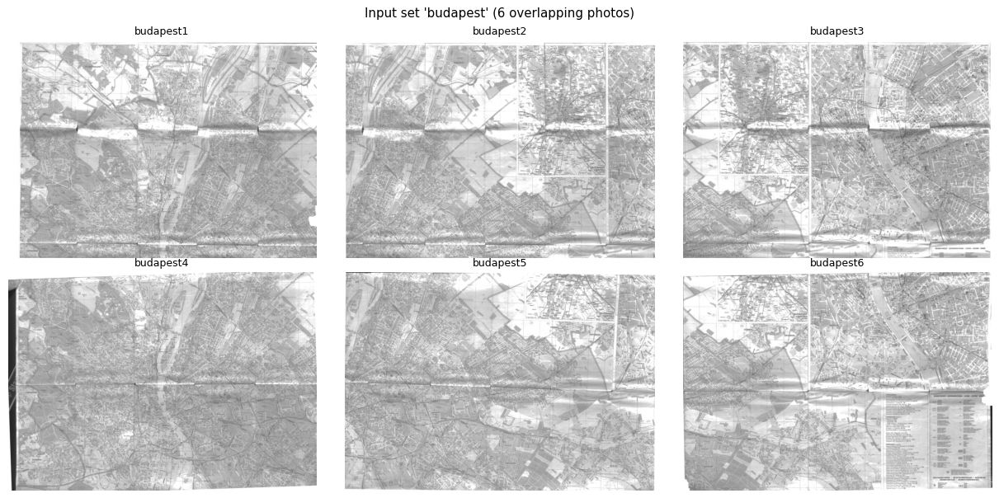

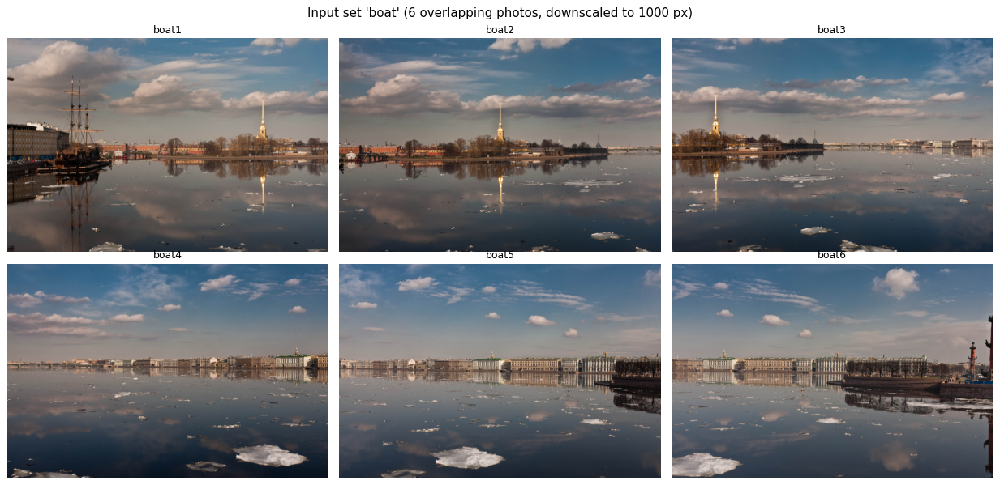

In [3]:
# We look at the raw input first, to make sure the photos really overlap and are in the format we expect.
show_images(IMAGES["budapest"], [f"budapest{i+1}" for i in range(6)], ncols=3, suptitle="Input set 'budapest' (6 overlapping photos)")
show_images(IMAGES["boat"], [f"boat{i+1}" for i in range(6)], ncols=3, suptitle="Input set 'boat' (6 overlapping photos, downscaled to 1000 px)")

## 2. Feature detection and description

We use **SIFT** (scale- and rotation-invariant, 128-D float descriptors). We call OpenCV only for the detector/descriptor itself; everything after it (matching, filtering, geometry) is our own code. **ORB** (binary descriptors, Hamming distance) is supported as an alternative and compared below.

In [4]:
def detect_features(img, detector="sift", n_features=4000):
    # We work on the grey image, since SIFT and ORB only use intensity.
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    # We support two detectors: SIFT (float descriptors, compared with the L2 distance) and ORB (binary descriptors,
    # compared with the Hamming distance).
    if detector == "sift":
        det, metric = cv2.SIFT_create(nfeatures=n_features), "l2"
    elif detector == "orb":
        det, metric = cv2.ORB_create(nfeatures=n_features, fastThreshold=10), "hamming"
    else:
        raise ValueError(detector)
    # We detect the keypoints and compute their descriptors in one call.
    kps, desc = det.detectAndCompute(gray, None)
    # We keep the keypoint coordinates as a plain float array, which is all the geometry stages need later.
    pts = np.array([k.pt for k in kps], dtype=np.float64).reshape(-1, 2)
    return {"pts": pts, "desc": desc, "kps": kps, "metric": metric, "size": (img.shape[1], img.shape[0])}


t0 = time.time()
# We run the detector on every image of every set once and we reuse these features everywhere below.
FEATS = {k: [detect_features(im) for im in v] for k, v in IMAGES.items()}
print(f"SIFT on all {sum(len(v) for v in IMAGES.values())} images: {time.time()-t0:.1f}s")
for k, v in FEATS.items():
    print(f"{k:10s} keypoints per image:", [len(f['pts']) for f in v])

SIFT on all 19 images: 2.3s
boat       keypoints per image: [1861, 1309, 1288, 1310, 1880, 2255]
budapest   keypoints per image: [4000, 4000, 4001, 4000, 4000, 4000]
newspaper  keypoints per image: [4001, 4000, 4000, 4000]
a          keypoints per image: [3560, 3774, 4000]


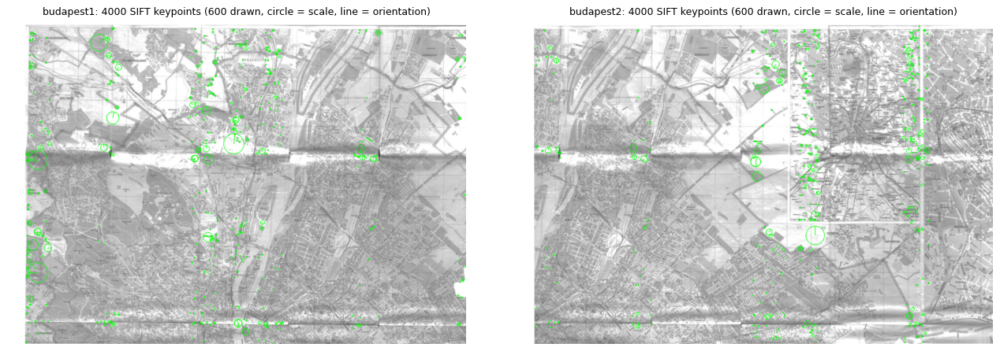

In [5]:
# We draw 600 of the budapest keypoints to see what SIFT picked (circle size = scale, line = orientation).
demo = IMAGES["budapest"]
vis = [cv2.drawKeypoints(demo[i], FEATS["budapest"][i]["kps"][:600], None, color=(0, 255, 0),
                         flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS) for i in (0, 1)]
show_images(vis, [f"budapest{i+1}: {len(FEATS['budapest'][i]['pts'])} SIFT keypoints (600 drawn, circle = scale, line = orientation)" for i in (0, 1)],
            cell=(7.5, 5.0))

## 3. Feature matching with our own matcher

For every descriptor in image A we find its two nearest neighbours in image B (exact brute force, squared-distance expansion `|a|^2 + |b|^2 - 2ab` evaluated with one matrix product).

* **Lowe's ratio test:** keep a match only if `d1 / d2 < 0.75`, where `d1`, `d2` are the distances to the best and second-best neighbour. A correct match is much closer than any alternative; a false one is not.
* **Mutual (cross) check:** additionally require that B's nearest neighbour of the matched descriptor is A's descriptor again.

In [6]:
def descriptor_distances(d1, d2, metric="l2"):
    """All-pairs distance matrix (n1 x n2). L2 for SIFT, Hamming for binary descriptors."""
    # For SIFT we use |a-b|^2 = |a|^2 + |b|^2 - 2ab, so we get all pairwise distances from one matrix product instead
    # of a double loop.
    if metric == "l2":
        a, b = d1.astype(np.float32), d2.astype(np.float32)
        sq = (a * a).sum(1)[:, None] + (b * b).sum(1)[None, :] - 2.0 * (a @ b.T)
        return np.sqrt(np.maximum(sq, 0.0))
    # For ORB we unpack the bits and count the differing bits, again with a single matrix product.
    if metric == "hamming":
        a = np.unpackbits(d1, axis=1).astype(np.float32)
        b = np.unpackbits(d2, axis=1).astype(np.float32)
        return a.sum(1)[:, None] + b.sum(1)[None, :] - 2.0 * (a @ b.T)
    raise ValueError(metric)


def match_descriptors(d1, d2, metric="l2", ratio=0.75, mutual=True):
    """Nearest-neighbour matching + Lowe ratio test (+ optional mutual check).
    Returns dict: all_nn (raw 1-NN pairs), ratio (d1/d2 per query), matches (filtered (i, j) pairs)."""
    # We compute the full distance matrix first, then we look for the two nearest neighbours of every descriptor.
    D = descriptor_distances(d1, d2, metric)
    n1 = D.shape[0]
    # We use argpartition to get the two smallest distances of each row without sorting the whole row.
    two = np.argpartition(D, 1, axis=1)[:, :2]               # indices of the 2 smallest (unordered)
    dd = np.take_along_axis(D, two, axis=1)
    order = np.argsort(dd, axis=1)
    two, dd = np.take_along_axis(two, order, 1), np.take_along_axis(dd, order, 1)
    nn = two[:, 0]
    # We compute Lowe's ratio: the distance to the best neighbour divided by the distance to the second best.
    rat = dd[:, 0] / np.maximum(dd[:, 1], 1e-12)
    # We keep a match only if the best neighbour is clearly better than the runner-up.
    keep = rat < ratio
    # We also require the match to be mutual: the nearest neighbour of B's descriptor must point back to the same
    # descriptor in A.
    if mutual:
        keep &= (D.argmin(axis=0)[nn] == np.arange(n1))
    idx = np.nonzero(keep)[0]
    return {"all_nn": np.stack([np.arange(n1), nn], 1), "ratio": rat, "dists": dd,
            "matches": np.stack([idx, nn[idx]], 1)}


def draw_matches(img1, img2, p1, p2, inlier=None, max_draw=120, seed=0, title=None):
    """Side-by-side match drawing. Green = inlier (or all, if `inlier` is None), red = outlier."""
    # We put the two images side by side on one canvas and we draw one line per match.
    h = max(img1.shape[0], img2.shape[0])
    canvas = np.zeros((h, img1.shape[1] + img2.shape[1], 3), np.uint8)
    canvas[:img1.shape[0], :img1.shape[1]] = img1
    canvas[:img2.shape[0], img1.shape[1]:] = img2
    # We draw only a random subset of the matches, otherwise the picture becomes unreadable.
    rng = np.random.default_rng(seed)
    sel = rng.permutation(len(p1))[:max_draw]
    for k in sel:
        ok = True if inlier is None else bool(inlier[k])
        # We colour the inliers green and the outliers red (BGR order, because we draw with OpenCV).
        col = (0, 220, 0) if ok else (0, 0, 255)
        a = tuple(int(round(v)) for v in p1[k])
        b = (int(round(p2[k][0])) + img1.shape[1], int(round(p2[k][1])))
        cv2.line(canvas, a, b, col, 1, cv2.LINE_AA)
        cv2.circle(canvas, a, 3, col, -1, cv2.LINE_AA)
        cv2.circle(canvas, b, 3, col, -1, cv2.LINE_AA)
    return canvas

matched in 0.34s | raw 1-NN pairs: 4000 | after ratio+mutual: 481


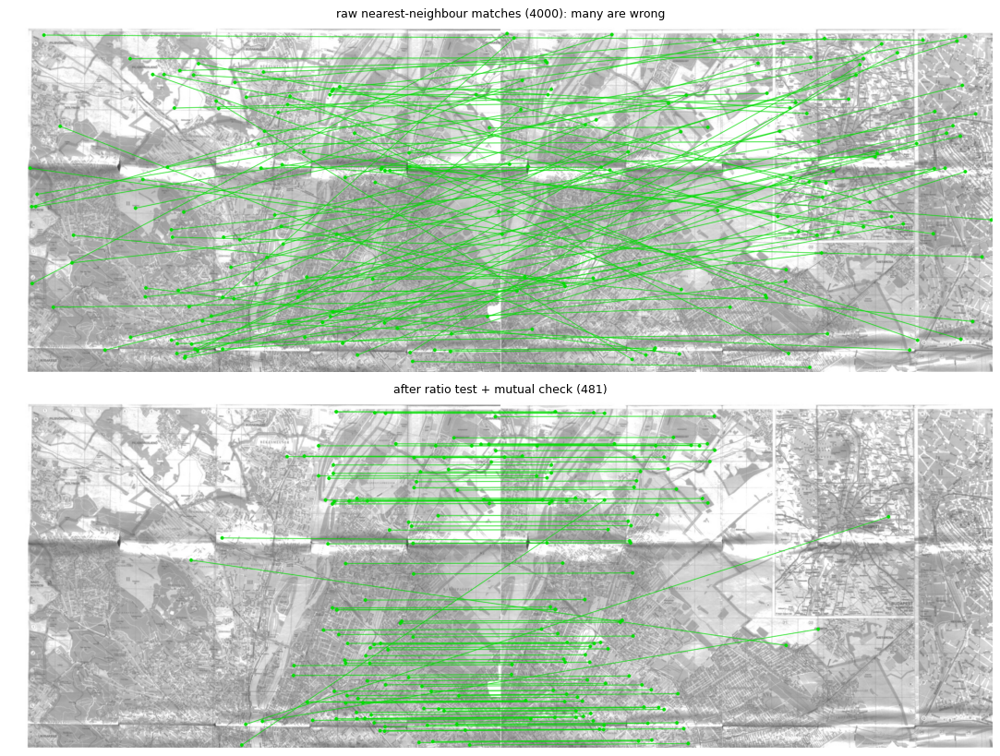

In [7]:
# We match the first two budapest tiles, with the ratio test at 0.75 and the mutual check switched on.
fa, fb = FEATS["budapest"][0], FEATS["budapest"][1]
t0 = time.time()
m = match_descriptors(fa["desc"], fb["desc"], fa["metric"], ratio=0.75, mutual=True)
print(f"matched in {time.time()-t0:.2f}s | raw 1-NN pairs: {len(m['all_nn'])} | after ratio+mutual: {len(m['matches'])}")
# We draw the raw nearest-neighbour matches first, to show how many wrong ones there are before any filtering.
raw = m["all_nn"]
img_raw = draw_matches(demo[0], demo[1], fa["pts"][raw[:, 0]], fb["pts"][raw[:, 1]], max_draw=100)
# Then we draw what is left after the ratio test and the mutual check.
mm = m["matches"]
img_flt = draw_matches(demo[0], demo[1], fa["pts"][mm[:, 0]], fb["pts"][mm[:, 1]], max_draw=100)
show_images([img_raw, img_flt],
            [f"raw nearest-neighbour matches ({len(raw)}): many are wrong", f"after ratio test + mutual check ({len(mm)})"],
            ncols=1, cell=(13, 4.6))

Even after the ratio test a few wrong matches survive. Removing them is the job of RANSAC, which needs a geometric model: the **homography**.

## 4. Homography estimation: normalized DLT + RANSAC

Two views of a planar scene, or two views from a camera that only **rotates** about its centre (the usual way to shoot a panorama), are related by a 3x3 projective transform `H` (8 degrees of freedom): `x' ~ H x` in homogeneous coordinates.

**DLT.** Each correspondence `(x, y) -> (u, v)` gives two linear equations in the 9 entries of `H`; stacking >= 4 correspondences gives `A h = 0`, solved by the right singular vector of the smallest singular value. **Hartley normalization** (translate the points to their centroid and scale to mean distance `sqrt(2)`) before solving makes this numerically well conditioned.

**RANSAC (MSAC scoring).** Repeatedly draw 4 matches, fit `H`, count how many matches agree with it within a pixel threshold, keep the best model, then re-fit on all its inliers. We (a) score with truncated squared error, (b) use the *symmetric* transfer error so degenerate models cannot hide, (c) reject degenerate (collinear) samples and (d) stop adaptively once `1 - (1 - w^4)^N > confidence`, with `w` the best inlier ratio so far. A short Levenberg-Marquardt polish then minimises the symmetric geometric error on the final inliers (only accepted if it lowers the MSAC score).

In [8]:
def apply_h(H, pts, return_w=False):
    """Apply a homography to Nx2 points."""
    pts = np.asarray(pts, dtype=np.float64).reshape(-1, 2)
    # We work in homogeneous coordinates: we append a 1, multiply by H, and then divide by the third coordinate.
    q = np.c_[pts, np.ones(len(pts))] @ np.asarray(H, dtype=np.float64).T
    w = q[:, 2]
    # We guard against a division by zero for points that land on the line at infinity.
    ws = np.where(np.abs(w) < 1e-12, 1e-12, w)
    out = q[:, :2] / ws[:, None]
    return (out, w) if return_w else out


def normalize_points(pts):
    """Hartley normalization: centroid -> origin, mean distance -> sqrt(2). Returns (normalized pts, 3x3 T)."""
    pts = np.asarray(pts, dtype=np.float64)
    # We move the centroid of the points to the origin ...
    c = pts.mean(axis=0)
    d = np.sqrt(((pts - c) ** 2).sum(axis=1)).mean()
    # ... and we scale the points so that their mean distance to the origin is sqrt(2) (Hartley normalization), which
    # keeps the linear system well conditioned.
    s = math.sqrt(2.0) / max(d, 1e-12)
    T = np.array([[s, 0, -s * c[0]], [0, s, -s * c[1]], [0, 0, 1.0]])
    return (pts - c) * s, T


def dlt_homography(src, dst):
    """Normalized Direct Linear Transform. src, dst: (n >= 4) x 2. Returns H (3x3, H[2,2] = 1) mapping src -> dst."""
    n = len(src)
    if n < 4:
        raise ValueError("need at least 4 correspondences")
    # We normalize both point sets first, and we undo the normalization at the end.
    ps, T1 = normalize_points(src)
    pd, T2 = normalize_points(dst)
    # We stack two equations per correspondence into a (2n x 9) matrix A, so that A h = 0.
    x, y, u, v = ps[:, 0], ps[:, 1], pd[:, 0], pd[:, 1]
    z, o = np.zeros(n), np.ones(n)
    A = np.empty((2 * n, 9))
    A[0::2] = np.stack([-x, -y, -o, z, z, z, u * x, u * y, u], axis=1)
    A[1::2] = np.stack([z, z, z, -x, -y, -o, v * x, v * y, v], axis=1)
    # We take the right singular vector of the smallest singular value as the solution h (with exactly 4 points we
    # need the full Vt, because the matrix is only 8 x 9).
    _, _, Vt = np.linalg.svd(A, full_matrices=(2 * n < 9))   # 4 points -> 8x9 system needs the full Vt
    Hn = Vt[-1].reshape(3, 3)
    # We undo the normalization, so that H maps the original pixel coordinates.
    H = np.linalg.inv(T2) @ Hn @ T1
    if abs(H[2, 2]) < 1e-12:
        return None
    # We scale H so that H[2, 2] = 1, because a homography is only defined up to scale.
    return H / H[2, 2]


def symmetric_transfer_error(H, src, dst):
    """Per-correspondence error in pixels: RMS of forward (src->dst) and backward (dst->src) transfer errors."""
    # We measure the error in both directions: how far src lands from dst under H, and how far dst lands from src
    # under the inverse of H.
    fwd = apply_h(H, src) - dst
    bwd = apply_h(np.linalg.inv(H), dst) - src
    return np.sqrt(0.5 * ((fwd ** 2).sum(1) + (bwd ** 2).sum(1)))


def _is_degenerate_sample(p, min_sin=0.02):
    """4 points are degenerate if any 3 are (nearly) collinear."""
    # We reject samples where 3 of the 4 points are almost on one line, because such a sample does not determine a
    # homography.
    span2 = max(((p[a] - p[b]) ** 2).sum() for a in range(4) for b in range(a + 1, 4))
    if span2 < 1e-9:
        return True
    for a, b, c in itertools.combinations(range(4), 3):
        u, v = p[b] - p[a], p[c] - p[a]
        if abs(u[0] * v[1] - u[1] * v[0]) / span2 < min_sin:
            return True
    return False


def refine_homography_lm(H, src, dst):
    """Levenberg-Marquardt polish of the symmetric geometric error (8 free parameters)."""
    # We polish the RANSAC result with Levenberg-Marquardt, using the 8 free entries of H (H[2, 2] stays fixed at 1).
    Hn = H / H[2, 2]
    x0 = Hn.ravel()[:8]

    def res(x):                                   # we use symmetric transfer residuals (the same error model as the RANSAC score)
        Hx = np.append(x, 1.0).reshape(3, 3)
        return np.concatenate([(apply_h(Hx, src) - dst).ravel(), (apply_h(np.linalg.inv(Hx), dst) - src).ravel()])

    sol = least_squares(res, x0, method="lm", x_scale="jac", max_nfev=200)
    Hr = np.append(sol.x, 1.0).reshape(3, 3)
    return Hr if np.all(np.isfinite(Hr)) else H


def ransac_homography(src, dst, thresh=3.0, confidence=0.999, max_iters=5000, min_iters=100, seed=0, polish=True):
    """Robustly fit H (src -> dst). Returns (H or None, inlier_mask, info dict)."""
    src, dst = np.asarray(src, np.float64), np.asarray(dst, np.float64)
    n = len(src)
    info = {"iterations": 0, "n": n}
    if n < 4:
        return None, np.zeros(n, bool), info
    # We seed the random generator, so every run of the notebook gives exactly the same result.
    rng = np.random.default_rng(seed)
    # We compare squared errors with the squared threshold, so we never need a square root inside the loop.
    t2 = thresh ** 2
    best_cost, best_H, best_inl = np.inf, None, np.zeros(n, bool)
    n_iter_needed, it = max_iters, 0
    # This is the main RANSAC loop: we draw 4 random matches, we fit H to them, and we count how many of the other
    # matches agree with it.
    while it < min(n_iter_needed, max_iters) or it < min_iters:
        it += 1
        idx = rng.choice(n, 4, replace=False)
        s4, d4 = src[idx], dst[idx]
        # We skip bad samples without counting them as a model.
        if _is_degenerate_sample(s4) or _is_degenerate_sample(d4):
            if it > 20 * max_iters:
                break
            continue
        H = dlt_homography(s4, d4)
        if H is None or not np.all(np.isfinite(H)) or abs(np.linalg.det(H)) < 1e-12:
            continue
        # We score the model with the MSAC cost: every match pays its squared error, capped at the squared
        # threshold, so an outlier always costs the same.
        err = symmetric_transfer_error(H, src, dst)
        cost = np.minimum(err ** 2, t2).sum()
        if cost < best_cost:
            best_cost, best_H, best_inl = cost, H, err < thresh
            # We update how many iterations we still need, so that with 99.9% confidence at least one sample
            # was free of outliers.
            w = best_inl.mean()
            if w >= 1.0 - 1e-9:
                n_iter_needed = it
            elif w > 0:
                n_iter_needed = math.log(1 - confidence) / math.log(max(1 - w ** 4, 1e-12))
    info["iterations"] = it
    if best_H is None or best_inl.sum() < 4:
        return None, np.zeros(n, bool), info
    # Once we have the best sample, we re-fit H on all of its inliers (DLT), we re-classify all matches, and we repeat
    # until the inlier set stops changing; then we polish with LM.
    H, inl = best_H, best_inl
    for _ in range(5):
        H2 = dlt_homography(src[inl], dst[inl])
        if H2 is None:
            break
        inl2 = symmetric_transfer_error(H2, src, dst) < thresh
        if inl2.sum() < 4:
            break
        converged = inl2.sum() == inl.sum() and np.all(inl2 == inl)
        H, inl = H2, inl2
        if converged:
            break
    if polish and inl.sum() >= 8:
        for _ in range(2):                         # we polish on the current inliers, we re-classify, and we polish once more
            Hp = refine_homography_lm(H, src[inl], dst[inl])
            errp = symmetric_transfer_error(Hp, src, dst)
            if np.minimum(errp ** 2, t2).sum() <= np.minimum(symmetric_transfer_error(H, src, dst) ** 2, t2).sum():
                H, inl = Hp, errp < thresh
    info["inlier_ratio"] = float(inl.mean())
    return H / H[2, 2], inl, info

RANSAC: 456 / 481 inliers (94.8%), 100 iterations, 30 ms, inlier RMSE 1.28px
H (budapest1 -> budapest2) =
 [[   1.0164    0.0031 -566.7492]
 [   0.0004    1.0057   -0.6657]
 [   0.        0.        1.    ]]
agreement with cv2.findHomography (reference only), mean corner difference: 3.257px | OpenCV inliers: 446


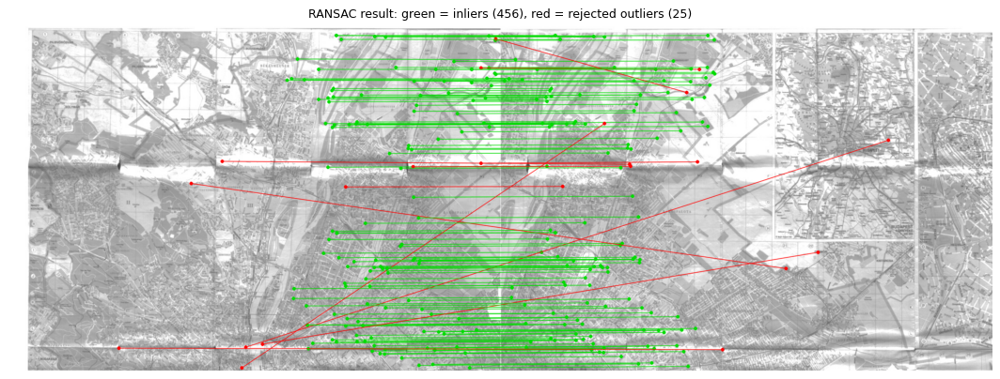

In [9]:
# We hand the filtered matches to RANSAC: src are the points in the first tile and dst are their partners in the second
# one.
src = fa["pts"][mm[:, 0]]; dst = fb["pts"][mm[:, 1]]
t0 = time.time()
H_demo, inl_demo, info_demo = ransac_homography(src, dst, thresh=3.0, seed=0)
dt = time.time() - t0
rmse = np.sqrt(np.mean(np.sum((apply_h(H_demo, src[inl_demo]) - dst[inl_demo]) ** 2, 1)))
print(f"RANSAC: {inl_demo.sum()} / {len(src)} inliers ({100*inl_demo.mean():.1f}%), {info_demo['iterations']} iterations, "
      f"{dt*1000:.0f} ms, inlier RMSE {rmse:.2f}px")
print("H (budapest1 -> budapest2) =\n", H_demo)
# As a sanity check only, we ask OpenCV for its own estimate on the same matches and we compare the two models.
H_cv, mask_cv = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
# We compare the two homographies by where they send the four image corners.
cor = np.array([[0, 0], [1000, 0], [1000, 700], [0, 700]], float)
print("agreement with cv2.findHomography (reference only), mean corner difference: "
      f"{np.linalg.norm(apply_h(H_demo, cor) - apply_h(H_cv, cor), axis=1).mean():.3f}px | OpenCV inliers: {int(mask_cv.sum())}")
show_images([draw_matches(demo[0], demo[1], src, dst, inlier=inl_demo, max_draw=140)],
            [f"RANSAC result: green = inliers ({inl_demo.sum()}), red = rejected outliers ({(~inl_demo).sum()})"], cell=(13, 4.6))

## 5. Image ordering, reference frame and global alignment

The photos are not assumed to be sorted. We run the matcher + RANSAC on **every pair**, keep a pair as an *edge* only if the geometry is convincing (Brown and Lowe's criterion `inliers > 8 + 0.3 * matches`, at least 15 inliers, and a plausible homography that keeps the image convex and right-way-up), and then:

1. build the **maximum spanning tree** of the inlier-count graph (the most reliable chain of overlaps, which also limits accumulated drift),
2. choose the **tree centre** as the reference image (fewest hops to every other image, so the least error accumulation),
3. **chain** the pairwise homographies to the reference: `H_k->ref = H_p->ref @ H_k->p` along the tree,
4. run a **global least-squares refinement** over *all* inlier correspondences of *all* edges (not only tree edges), so loop inconsistencies are spread out instead of accumulating. This is a homography-only version of bundle adjustment.

In [10]:
def plausible_homography(H, w, h, lo=0.1, hi=10.0):
    """The warped image rectangle must stay in front of the camera, convex, keep its orientation and a sane area."""
    # We push the four image corners through H, because a believable H must keep them in front of the camera, convex,
    # with the same orientation and with a sane area.
    corners = np.array([[0, 0], [w, 0], [w, h], [0, h]], float)
    # We keep the homogeneous weights too, so we can detect corners that end up behind the camera.
    p, den = apply_h(H, corners, return_w=True)
    if np.any(den <= 0) or not np.all(np.isfinite(p)):
        return False
    # We check the turn direction at every corner: a flipped or twisted quadrilateral means the estimate is wrong.
    for k in range(4):
        a, b, c = p[k], p[(k + 1) % 4], p[(k + 2) % 4]
        if (b[0] - a[0]) * (c[1] - b[1]) - (b[1] - a[1]) * (c[0] - b[0]) <= 0:
            return False
    # We compare the area of the warped quadrilateral with the original one (shoelace formula).
    area = 0.5 * abs(sum(p[k][0] * p[(k + 1) % 4][1] - p[(k + 1) % 4][0] * p[k][1] for k in range(4)))
    return lo < area / (w * h) < hi


def estimate_pair(fa, fb, ratio=0.75, thresh=3.0, min_inliers=15, seed=0):
    """Match two images and fit H (a -> b). Returns a dict with all statistics."""
    # For every pair we match the descriptors (ratio test plus mutual check) and then we robustly fit a homography.
    m = match_descriptors(fa["desc"], fb["desc"], fa["metric"], ratio=ratio, mutual=True)["matches"]
    r = {"n_kp": (len(fa["pts"]), len(fb["pts"])), "n_match": len(m), "H": None, "inliers": 0,
         "rmse": np.nan, "accepted": False, "src": np.zeros((0, 2)), "dst": np.zeros((0, 2))}
    if len(m) < 8:
        return r
    src, dst = fa["pts"][m[:, 0]], fb["pts"][m[:, 1]]
    # RANSAC removes the wrong matches that survived the ratio test.
    H, inl, info = ransac_homography(src, dst, thresh=thresh, seed=seed)
    if H is None:
        return r
    # We store the inlier correspondences too, because the global refinement needs them later.
    r.update(H=H, inliers=int(inl.sum()), src=src[inl], dst=dst[inl], iterations=info["iterations"],
             rmse=float(np.sqrt(np.mean(np.sum((apply_h(H, src[inl]) - dst[inl]) ** 2, 1)))))
    w, h = fa["size"]
    # We accept the pair as a real overlap only if it passes Brown and Lowe's test (inliers > 8 + 0.3 * matches), has
    # enough inliers and has a plausible H.
    r["accepted"] = bool(r["inliers"] >= min_inliers and r["inliers"] > 8 + 0.3 * len(m) and plausible_homography(H, w, h))
    return r


def build_match_graph(feats, **kw):
    n = len(feats)
    # We try every pair of images, because we do not trust the file order; W[i, j] stores the inlier count of every
    # accepted overlap.
    pairs, W = {}, np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            pairs[(i, j)] = estimate_pair(feats[i], feats[j], **kw)
            if pairs[(i, j)]["accepted"]:
                W[i, j] = W[j, i] = pairs[(i, j)]["inliers"]
    return pairs, W


def connected_components(W):
    # We find the groups of images that are linked by accepted overlaps (a simple depth-first search).
    n, seen, comps = len(W), set(), []
    for s in range(n):
        if s in seen:
            continue
        comp, stack = [], [s]
        seen.add(s)
        while stack:
            u = stack.pop()
            comp.append(u)
            for v in np.nonzero(W[u] > 0)[0]:
                if int(v) not in seen:
                    seen.add(int(v))
                    stack.append(int(v))
        comps.append(sorted(comp))
    return comps


def max_spanning_tree(W, nodes):
    """Prim's algorithm on the inlier-count weights. Returns a list of (parent, child) edges."""
    nodes = list(nodes)
    # We grow the tree greedily from one image, always adding the strongest remaining link (Prim's algorithm on the
    # inlier counts).
    in_tree, edges = {nodes[0]}, []
    while len(in_tree) < len(nodes):
        best, bw = None, -1
        for u in in_tree:
            for v in nodes:
                if v not in in_tree and W[u, v] > bw:
                    best, bw = (u, v), W[u, v]
        edges.append(best)
        in_tree.add(best[1])
    return edges


def tree_center(edges, nodes):
    """Node with the smallest eccentricity (fewest hops to the farthest image)."""
    # We pick as reference the image with the fewest hops to the farthest image, so that errors accumulate along the
    # shortest possible chains.
    adj = {k: [] for k in nodes}
    for a, b in edges:
        adj[a].append(b); adj[b].append(a)

    def ecc(s):
        dist, queue = {s: 0}, [s]
        for u in queue:
            for v in adj[u]:
                if v not in dist:
                    dist[v] = dist[u] + 1
                    queue.append(v)
        return max(dist.values())

    return min(nodes, key=lambda k: (ecc(k), k))


def pair_H(pairs, i, j):
    """Homography mapping image i -> image j (uses the stored i<j estimate or its inverse)."""
    # We only stored each pair once (i < j), so for the other direction we invert the homography.
    if i < j:
        return pairs[(i, j)]["H"]
    return np.linalg.inv(pairs[(j, i)]["H"])


def chain_homographies(pairs, edges, ref):
    adj = {}
    for a, b in edges:
        adj.setdefault(a, []).append(b); adj.setdefault(b, []).append(a)
    # We walk outward from the reference image and we multiply the pairwise homographies along the tree.
    Hs, queue = {ref: np.eye(3)}, [ref]
    for u in queue:
        for v in adj.get(u, []):
            if v not in Hs:
                # To map image v to the reference, we first map it to its neighbour u and then we use u's
                # own homography to the reference.
                Hv = Hs[u] @ pair_H(pairs, v, u)             # v -> u -> ref
                Hs[v] = Hv / Hv[2, 2]
                queue.append(v)
    return Hs


def refine_global(Hs, pairs, W, ref):
    """Jointly refine all H_k->ref by minimising robust transfer error over all inlier matches of all accepted edges."""
    # Chaining pairwise homographies lets small errors add up, so we now refine all of them together.
    ids = sorted(k for k in Hs if k != ref)
    # We use the inlier matches of every accepted pair (not only the tree edges), so that loops of overlapping images
    # constrain each other.
    edges = [(i, j, p["src"], p["dst"]) for (i, j), p in pairs.items() if W[i, j] > 0 and i in Hs and j in Hs]
    if not ids or not edges:
        return Hs, {"before": np.nan, "after": np.nan, "used": False}
    # The unknowns are the 8 free entries of H for every image except the reference, which stays fixed at the
    # identity.
    x0 = np.concatenate([(Hs[k] / Hs[k][2, 2]).ravel()[:8] for k in ids])

    def unpack(x):
        out = {ref: np.eye(3)}
        for n, k in enumerate(ids):
            out[k] = np.append(x[8 * n:8 * n + 8], 1.0).reshape(3, 3)
        return out

    # The residuals are how far every matched point lands from its partner, measured in both directions.
    def residuals(x):
        Hx, res = unpack(x), []
        for i, j, pi, pj in edges:
            res.append((apply_h(np.linalg.inv(Hx[j]) @ Hx[i], pi) - pj).ravel())
            res.append((apply_h(np.linalg.inv(Hx[i]) @ Hx[j], pj) - pi).ravel())
        return np.concatenate(res)

    def stats(r):
        e = np.hypot(r[0::2], r[1::2])
        return float(np.sqrt(np.mean(e ** 2)))

    # We remember the starting error, so we only keep the refinement if it really helps.
    r0 = residuals(x0)
    try:
        # We minimise with a robust (soft L1) loss, so that a few leftover bad matches cannot pull the solution
        # away.
        sol = least_squares(residuals, x0, loss="soft_l1", f_scale=1.5, x_scale="jac", max_nfev=60)
    except Exception:
        return Hs, {"before": stats(r0), "after": stats(r0), "used": False}
    r1 = residuals(sol.x)
    info = {"before": stats(r0), "after": stats(r1), "used": False}
    # We accept the refined homographies only if the error went down.
    if np.all(np.isfinite(sol.x)) and info["after"] < info["before"]:
        info["used"] = True
        return {k: v / v[2, 2] for k, v in unpack(sol.x).items()}, info
    return Hs, info

=== budapest: 7.3s | component [1, 2, 3, 4, 5, 6] | reference image 2 | tree [(1, 4), (4, 5), (5, 2), (2, 3), (3, 6)]
    global refinement: mean transfer error 2.957px -> 1.342px (applied: True)


=== boat: 9.4s | component [1, 2, 3, 4, 5, 6] | reference image 3 | tree [(1, 2), (2, 3), (3, 4), (4, 5), (5, 6)]
    global refinement: mean transfer error 1.515px -> 0.976px (applied: True)
    pair   kp A   kp B  matches  inliers  ratio  RMSE px  edge
     1-2   1861   1309      553      515   0.93     0.44  ACCEPT
     1-3   1861   1288      265      239   0.90     0.50  ACCEPT
     1-4   1861   1310       14        5   0.36     0.00  -
     1-5   1861   1880       19        5   0.26     0.00  -
     1-6   1861   2255       19        5   0.26     0.00  -
     2-3   1309   1288      450      366   0.81     0.50  ACCEPT
     2-4   1309   1310       34       20   0.59     0.59  ACCEPT
     2-5   1309   1880       13        4   0.31     0.00  -
     2-6   1309   2255       12        4   0.33     0.00  -
     3-4   1288   1310      255      226   0.89     0.57  ACCEPT
     3-5   1288   1880       50       38   0.76     0.42  ACCEPT
     3-6   1288   2255       19        5   0.26     0.0

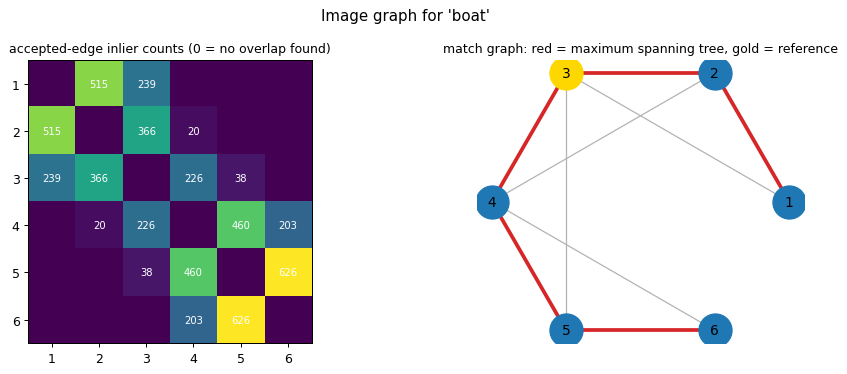

In [11]:
def run_alignment(feats, sizes_ok=True, refine=True, **kw):
    # Step 1: we match every pair of images and we build the overlap graph.
    pairs, W = build_match_graph(feats, **kw)
    # Step 2: we keep the largest connected group of images; anything that is not linked to it is left out, because it
    # does not overlap the others.
    comps = connected_components(W)
    comp = max(comps, key=lambda c: (len(c), sum(W[a, b] for a in c for b in c)))
    # Step 3: we find the strongest chain of overlaps (the spanning tree) and we take the image at its centre as the
    # reference.
    edges = max_spanning_tree(W, comp) if len(comp) > 1 else []
    ref = tree_center(edges, comp) if len(comp) > 1 else comp[0]
    # Step 4: we chain the pairwise homographies to the reference, and then we refine them globally.
    Hs = chain_homographies(pairs, edges, ref)
    Hs_chain = dict(Hs)
    rinfo = {"before": np.nan, "after": np.nan, "used": False}
    if refine and len(comp) > 1:
        Hs, rinfo = refine_global(Hs, pairs, W, ref)
    return {"pairs": pairs, "W": W, "component": comp, "dropped": [k for k in range(len(feats)) if k not in comp],
            "tree": edges, "ref": ref, "H": Hs, "H_chain": Hs_chain, "refine": rinfo}


def print_pair_table(pairs, W, names=None):
    print(f"{'pair':>8s} {'kp A':>6s} {'kp B':>6s} {'matches':>8s} {'inliers':>8s} {'ratio':>6s} {'RMSE px':>8s}  edge")
    for (i, j), p in pairs.items():
        ratio = p["inliers"] / max(p["n_match"], 1)
        tag = "ACCEPT" if p["accepted"] else "-"
        nm = f"{(names[i] if names else i+1)}-{(names[j] if names else j+1)}"
        print(f"{nm:>8s} {p['n_kp'][0]:6d} {p['n_kp'][1]:6d} {p['n_match']:8d} {p['inliers']:8d} {ratio:6.2f} {p['rmse']:8.2f}  {tag}")


def plot_graph(res, title):
    n = len(res["W"])
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    im = ax[0].imshow(res["W"], cmap="viridis")
    ax[0].set_xticks(range(n)); ax[0].set_yticks(range(n))
    ax[0].set_xticklabels(range(1, n + 1)); ax[0].set_yticklabels(range(1, n + 1))
    for i in range(n):
        for j in range(n):
            if res["W"][i, j] > 0:
                ax[0].text(j, i, int(res["W"][i, j]), ha="center", va="center", color="w", fontsize=8)
    ax[0].set_title("accepted-edge inlier counts (0 = no overlap found)")
    # We place the images on a circle to draw the graph; the thick red edges are the spanning tree.
    ang = np.linspace(0, 2 * np.pi, n, endpoint=False)
    xy = np.c_[np.cos(ang), np.sin(ang)]
    tree = {tuple(sorted(e)) for e in res["tree"]}
    for (i, j), p in res["pairs"].items():
        if res["W"][i, j] > 0:
            ax[1].plot(*zip(xy[i], xy[j]), color="tab:red" if (i, j) in tree else "0.7", lw=3 if (i, j) in tree else 1, zorder=1)
    for k in range(n):
        ax[1].scatter(*xy[k], s=700, color="gold" if k == res["ref"] else ("lightgray" if k in res["dropped"] else "tab:blue"), zorder=2)
        ax[1].text(*xy[k], str(k + 1), ha="center", va="center", color="k", zorder=3, fontsize=11)
    ax[1].set_aspect("equal"); ax[1].axis("off")
    ax[1].set_title("match graph: red = maximum spanning tree, gold = reference")
    fig.suptitle(title)
    plt.tight_layout(); plt.show()


t0 = time.time()
# We run the alignment for two sets, so we can compare a 2D grid of tiles (budapest) with a one-dimensional pan (boat).
ALIGN = {}
for _k in ("budapest", "boat"):
    ALIGN[_k] = run_alignment(FEATS[_k])
    print(f"=== {_k}: {time.time()-t0:.1f}s | component {[c+1 for c in ALIGN[_k]['component']]} | reference image {ALIGN[_k]['ref']+1} "
          f"| tree {[(a+1, b+1) for a, b in ALIGN[_k]['tree']]}")
    print(f"    global refinement: mean transfer error {ALIGN[_k]['refine']['before']:.3f}px -> {ALIGN[_k]['refine']['after']:.3f}px (applied: {ALIGN[_k]['refine']['used']})")
print_pair_table(ALIGN["boat"]["pairs"], ALIGN["boat"]["W"])
plot_graph(ALIGN["boat"], "Image graph for 'boat'")

## 6. Warping into a common panorama frame

**Canvas.** Every image's border is pushed through its homography to the reference plane to find the panorama's bounding box.

**Projection.** If a panorama spans a wide angle, a flat (planar) reference image stretches the outer photos badly. For a camera that only rotates, `H = K R K^-1`, so we can recover the **focal length** `f` by finding the value that makes every pairwise `K^-1 H K` closest to a true rotation (orthogonal matrix). With `f` known we can optionally re-project the mosaic onto a **cylinder** (`x = f*theta`), which keeps wide panoramas undistorted. The rule `projection="auto"` chooses cylindrical when the rotation model fits well and the planar mosaic would exceed ~75 degrees of horizontal field of view; flat scenes (documents, maps) stay planar.

**Warp.** We do *inverse* warping: for each canvas pixel we compute where it comes from in the source image and sample it with our own **bilinear interpolation** (forward warping leaves holes).

In [12]:
def rotation_fit_residual(Hij, f, ci, cj):
    """How far is K_j^-1 H K_i from a pure rotation? (Frobenius norm of R^T R - I after det normalisation)."""
    # We build the camera matrices K of both images, with the principal point in the image centre.
    Ki = np.array([[f, 0, ci[0]], [0, f, ci[1]], [0, 0, 1.0]])
    Kj = np.array([[f, 0, cj[0]], [0, f, cj[1]], [0, 0, 1.0]])
    # If the camera only rotated, then K_j^-1 H K_i is a rotation matrix (up to scale).
    A = np.linalg.inv(Kj) @ Hij @ Ki
    d = np.linalg.det(A)
    if d <= 0:
        return 10.0
    # We remove the unknown scale by forcing the determinant to 1.
    A = A / np.cbrt(d)
    # A rotation satisfies R^T R = I, so the distance from the identity tells us how wrong the focal length is.
    return float(np.linalg.norm(A.T @ A - np.eye(3)))


def estimate_focal(res, sizes):
    """1-D search of the focal length (px) that best explains all edge homographies as camera rotations."""
    Hs = res["H"]
    edges = [(i, j) for (i, j) in res["pairs"] if res["W"][i, j] > 0 and i in Hs and j in Hs]
    if not edges:
        return None, np.inf
    # We use every accepted pair of images: we express its homography between the two images, and then we ask which
    # focal length makes it look like a rotation.
    items = []
    for i, j in edges:
        Hij = np.linalg.inv(Hs[j]) @ Hs[i]
        ci = (sizes[i][0] / 2, sizes[i][1] / 2); cj = (sizes[j][0] / 2, sizes[j][1] / 2)
        items.append((Hij, ci, cj, math.sqrt(res["pairs"][(i, j)]["inliers"])))
    wsum = sum(it[3] for it in items)

    def cost(f):
        return sum(it[3] * rotation_fit_residual(it[0], f, it[1], it[2]) for it in items) / wsum

    scale = max(max(s) for s in sizes)
    # We search the focal length in two steps: first a coarse grid over a wide range, then a local refinement around
    # the best value.
    grid = np.geomspace(0.3, 6.0, 240) * scale
    c = np.array([cost(f) for f in grid])
    k = int(np.argmin(c))
    lo, hi = grid[max(k - 1, 0)], grid[min(k + 1, len(grid) - 1)]
    # We refine between the two grid neighbours of the best value.
    sol = minimize_scalar(cost, bounds=(lo, hi), method="bounded")
    return float(sol.x), float(sol.fun)


# We implement the two panorama frames as small classes with the same interface: forward() maps reference-plane pixels to
# canvas coordinates and inverse() does the opposite.
class PlanarProjection:
    name = "planar"
    f = None

    def forward(self, q):                    # reference-plane px -> canvas coordinates
        return q

    def inverse(self, uv):                   # canvas coordinates -> reference-plane px, validity
        return uv, np.ones(len(uv), bool)


# In the cylindrical frame x becomes f * theta, which keeps wide panoramas from being stretched at the edges.
class CylindricalProjection:
    name = "cylindrical"

    def __init__(self, f, c):
        self.f, self.c = float(f), np.asarray(c, float)

    def forward(self, q):
        # We measure from the principal point, then we convert the horizontal position to an angle and the
        # vertical position to a height on the cylinder.
        x, y = q[:, 0] - self.c[0], q[:, 1] - self.c[1]
        return np.c_[self.f * np.arctan2(x, self.f) + self.c[0], self.f * y / np.hypot(x, self.f) + self.c[1]]

    def inverse(self, uv):
        # We go the other way here: from the angle theta back to the plane (with tan), and from the height back to
        # the plane (dividing by cos).
        th = (uv[:, 0] - self.c[0]) / self.f
        # We mark rays at almost 90 degrees as invalid, because they would hit the plane at infinity.
        ok = np.abs(th) < 1.45
        th = np.where(ok, th, 0.0)
        x = self.f * np.tan(th)
        y = (uv[:, 1] - self.c[1]) / np.cos(th)
        return np.c_[x + self.c[0], y + self.c[1]], ok


def border_points(w, h, n=80):
    # We sample points along the four edges of an image; where they land tells us the footprint of the image on the
    # canvas.
    t = np.linspace(0, 1, n)
    return np.concatenate([np.c_[t * w, np.zeros(n)], np.c_[np.full(n, w), t * h], np.c_[t * w, np.full(n, h)], np.c_[np.zeros(n), t * h]])


def horizontal_span_deg(Hs, sizes, ref, f):
    """Angular extent (deg) of the mosaic seen from the reference camera, assuming focal length f."""
    # We measure the angle of every border point as seen from the reference camera; the spread of those angles is the
    # field of view of the mosaic.
    c = np.array([sizes[ref][0] / 2, sizes[ref][1] / 2])
    ang = []
    for k, H in Hs.items():
        q, den = apply_h(H, border_points(*sizes[k]), return_w=True)
        if np.any(den <= 0):
            return 180.0
        ang.append(np.arctan((q[:, 0] - c[0]) / f))
    ang = np.concatenate(ang)
    return float(np.degrees(ang.max() - ang.min()))


def bilinear_sample(img, x, y):
    """Own bilinear interpolation. img: HxWxC (any dtype). Returns float32 samples and a validity mask."""
    h, w = img.shape[:2]
    # We only sample inside the source image; everything else is marked invalid (it becomes a black border).
    valid = (x >= 0) & (x <= w - 1) & (y >= 0) & (y <= h - 1) & np.isfinite(x) & np.isfinite(y)
    xs = np.clip(np.where(valid, x, 0.0), 0, w - 1.000001)
    ys = np.clip(np.where(valid, y, 0.0), 0, h - 1.000001)
    # We find the four pixels around each sample position and the fractional offsets inside that cell.
    x0, y0 = np.floor(xs).astype(np.int32), np.floor(ys).astype(np.int32)
    fx, fy = (xs - x0).astype(np.float32)[..., None], (ys - y0).astype(np.float32)[..., None]
    a, b = img[y0, x0].astype(np.float32), img[y0, x0 + 1].astype(np.float32)
    c, d = img[y0 + 1, x0].astype(np.float32), img[y0 + 1, x0 + 1].astype(np.float32)
    # Then we mix the four neighbours: first along x, then along y (this is bilinear interpolation).
    out = (a * (1 - fx) + b * fx) * (1 - fy) + (c * (1 - fx) + d * fx) * fy
    return out, valid


def layout_canvas(sizes, Hs, proj, max_side=5000):
    """Bounding box of all warped images in projection coordinates, and the output scale."""
    # We warp the border of every image into the panorama frame, to find out how big the canvas must be.
    boxes = {}
    for k, H in Hs.items():
        q, den = apply_h(H, border_points(*sizes[k]), return_w=True)
        if np.any(den <= 0):
            raise ValueError(f"image {k+1} falls behind the reference plane; use projection='cylindrical'")
        uv = proj.forward(q)
        boxes[k] = (uv[:, 0].min(), uv[:, 1].min(), uv[:, 0].max(), uv[:, 1].max())
    umin = min(b[0] for b in boxes.values()); vmin = min(b[1] for b in boxes.values())
    umax = max(b[2] for b in boxes.values()); vmax = max(b[3] for b in boxes.values())
    # If the panorama would be huge, we scale the output down, so memory stays under control.
    scale = min(1.0, max_side / max(umax - umin, vmax - vmin))
    Wc, Hc = int(math.ceil((umax - umin) * scale)) + 1, int(math.ceil((vmax - vmin) * scale)) + 1
    return {"origin": (umin, vmin), "scale": scale, "size": (Wc, Hc), "boxes": boxes}


def warp_to_canvas(img, H, proj, layout):
    """Inverse-warp one image into a tight bounding-box patch of the canvas. Returns (patch uint8, mask bool, (x0, y0))."""
    # We only compute the part of the canvas that this image can cover (its bounding box), instead of the whole
    # canvas.
    (umin, vmin), s = layout["origin"], layout["scale"]
    Wc, Hc = layout["size"]
    q, den = apply_h(H, border_points(img.shape[1], img.shape[0]), return_w=True)
    uv = proj.forward(q)
    xy = (uv - np.array([umin, vmin])) * s
    x0, y0 = max(int(np.floor(xy[:, 0].min())) - 1, 0), max(int(np.floor(xy[:, 1].min())) - 1, 0)
    x1, y1 = min(int(np.ceil(xy[:, 0].max())) + 2, Wc), min(int(np.ceil(xy[:, 1].max())) + 2, Hc)
    # We create one grid point for every canvas pixel inside that box.
    gx, gy = np.meshgrid(np.arange(x0, x1, dtype=np.float64), np.arange(y0, y1, dtype=np.float64))
    uvg = np.c_[gx.ravel() / s + umin, gy.ravel() / s + vmin]
    # We work backwards (inverse warping): for every canvas pixel we find out which source pixel it comes from. This
    # leaves no holes, unlike pushing the source pixels forward.
    qg, ok = proj.inverse(uvg)
    # We map the reference-plane point into the source image with the inverse homography.
    src, w = apply_h(np.linalg.inv(H), qg, return_w=True)
    sx, sy = src[:, 0].reshape(gx.shape), src[:, 1].reshape(gx.shape)
    # We read the colours with our own bilinear interpolation.
    samp, valid = bilinear_sample(img, sx, sy)
    valid &= (w > 0).reshape(gx.shape) & ok.reshape(gx.shape)
    # We store the result as a small uint8 patch plus a validity mask, which keeps the memory low.
    patch = np.clip(np.rint(samp), 0, 255).astype(np.uint8)
    patch[~valid] = 0
    return patch, valid, (x0, y0)


def make_projection(res, sizes, mode="auto", verbose=True):
    ref, Hs = res["ref"], res["H"]
    # First we estimate the focal length and how well the rotation model fits.
    f, fit = estimate_focal(res, sizes)
    c = (sizes[ref][0] / 2, sizes[ref][1] / 2)
    info = {"f": f, "fit": fit, "span_deg": np.nan}
    if f is not None:
        info["span_deg"] = horizontal_span_deg(Hs, sizes, ref, f)
    # For the automatic choice we use the cylinder only when the camera clearly rotated (low misfit) and the planar
    # mosaic would span more than 75 degrees; flat scenes stay planar.
    if mode == "auto":
        use_cyl = f is not None and fit < 0.12 and info["span_deg"] > 75
        mode = "cylindrical" if use_cyl else "planar"
    if verbose:
        print(f"    focal estimate f = {f if f is None else round(f, 1)} px, rotation-model misfit {fit:.3f}, planar span {info['span_deg']:.0f} deg -> {mode}")
    if mode == "cylindrical":
        if f is None:
            raise ValueError("cylindrical projection needs a focal length estimate")
        return CylindricalProjection(f, c), info
    return PlanarProjection(), info

## 7. Blending and exposure compensation

Warping aligns the *geometry*, but seams stay visible for two reasons: photos have different **exposure**, and small residual **misalignment**. We handle both:

* **Gain compensation** (Brown and Lowe): find one gain per image (per colour channel) so that the mean intensities in the overlaps agree, by solving a small linear least-squares problem with a prior that keeps gains near 1.
* **Feathering:** weighted average where each image's weight is its distance to its own border, so the transition is gradual. Cheap, but it blurs fine detail and ghosts slight misalignments across the whole overlap.
* **Multi-band blending:** split each image into a Laplacian pyramid, blend **low frequencies over a wide region and high frequencies over a narrow one** (weights are blurred more at coarse levels), then collapse the pyramid. Large-scale colour/brightness differences are smoothed away but edges and texture stay sharp.

In [13]:
def overlap_stats(pa, ma, oa, pb, mb, ob, min_pixels=400):
    # We intersect the two patches in canvas coordinates, to find the region where both images have pixels.
    x0, y0 = max(oa[0], ob[0]), max(oa[1], ob[1])
    x1, y1 = min(oa[0] + pa.shape[1], ob[0] + pb.shape[1]), min(oa[1] + pa.shape[0], ob[1] + pb.shape[0])
    if x1 <= x0 or y1 <= y0:
        return None
    A = pa[y0 - oa[1]:y1 - oa[1], x0 - oa[0]:x1 - oa[0]]
    B = pb[y0 - ob[1]:y1 - ob[1], x0 - ob[0]:x1 - ob[0]]
    # We only use pixels that are valid in both images, and we average the colour over that region (per channel).
    m = ma[y0 - oa[1]:y1 - oa[1], x0 - oa[0]:x1 - oa[0]] & mb[y0 - ob[1]:y1 - ob[1], x0 - ob[0]:x1 - ob[0]]
    n = int(m.sum())
    if n < min_pixels:
        return None
    return n, A[m].astype(np.float64).mean(0), B[m].astype(np.float64).mean(0)


def compute_gains(patches, masks, offsets, sigma_n=10.0, sigma_g=0.1):
    """Per-image, per-channel gains minimising  sum_ij N_ij [ (g_i I_ij - g_j I_ji)^2 / sn^2 + (1 - g_i)^2 / sg^2 ]."""
    # For every overlapping pair we measure how many pixels overlap and what mean colour each image has there.
    k = len(patches)
    N, I = np.zeros((k, k)), np.zeros((k, k, 3))
    for i in range(k):
        for j in range(i + 1, k):
            st = overlap_stats(patches[i], masks[i], offsets[i], patches[j], masks[j], offsets[j])
            if st is not None:
                N[i, j] = N[j, i] = st[0]
                I[i, j], I[j, i] = st[1], st[2]
    # We solve one small linear system per colour channel: neighbouring images should agree in the overlap, while a
    # weak prior keeps every gain near 1 (which also fixes the overall brightness).
    gains = np.ones((k, 3))
    for c in range(3):
        A, b = np.zeros((k, k)), np.zeros(k)
        for i in range(k):
            for j in range(k):
                if N[i, j] > 0:
                    A[i, i] += N[i, j] * (2 * I[i, j, c] ** 2 / sigma_n ** 2 + 1 / sigma_g ** 2)
                    A[i, j] -= 2 * N[i, j] * I[i, j, c] * I[j, i, c] / sigma_n ** 2
                    b[i] += N[i, j] / sigma_g ** 2
        if np.any(np.diag(A) > 0):
            gains[:, c] = np.linalg.solve(A + 1e-9 * np.eye(k), b)
    return gains, N


def overlap_error(patches, masks, offsets, gains=None):
    """Mean absolute grey-level difference over all pairwise overlaps (a seam/exposure consistency metric)."""
    # This is our measure of exposure consistency: the average absolute grey-level difference between the images where
    # they overlap.
    tot, cnt = 0.0, 0
    for i in range(len(patches)):
        for j in range(i + 1, len(patches)):
            x0, y0 = max(offsets[i][0], offsets[j][0]), max(offsets[i][1], offsets[j][1])
            x1 = min(offsets[i][0] + patches[i].shape[1], offsets[j][0] + patches[j].shape[1])
            y1 = min(offsets[i][1] + patches[i].shape[0], offsets[j][1] + patches[j].shape[0])
            if x1 <= x0 or y1 <= y0:
                continue
            sa = (slice(y0 - offsets[i][1], y1 - offsets[i][1]), slice(x0 - offsets[i][0], x1 - offsets[i][0]))
            sb = (slice(y0 - offsets[j][1], y1 - offsets[j][1]), slice(x0 - offsets[j][0], x1 - offsets[j][0]))
            m = masks[i][sa] & masks[j][sb]
            if m.sum() < 400:
                continue
            A, B = patches[i][sa][m].astype(np.float64), patches[j][sb][m].astype(np.float64)
            if gains is not None:
                A, B = np.clip(A * gains[i], 0, 255), np.clip(B * gains[j], 0, 255)
            tot += np.abs(A - B).mean() * m.sum(); cnt += m.sum()
    return tot / cnt if cnt else np.nan


def apply_gains(patches, masks, gains):
    out = []
    for p, m, g in zip(patches, masks, gains):
        # We multiply each channel by its gain and we clip to the valid 0..255 range.
        q = np.clip(p.astype(np.float32) * g.astype(np.float32), 0, 255).astype(np.uint8)
        q[~m] = 0
        out.append(q)
    return out


def dist_to_border(mask):
    """Euclidean distance of each valid pixel to the nearest invalid pixel / patch border."""
    # We pad the mask by one pixel, so the patch border counts as an edge; then the distance transform gives every
    # pixel its distance to the nearest invalid pixel.
    pad = np.pad(mask.astype(np.uint8), 1)
    return cv2.distanceTransform(pad, cv2.DIST_L2, 3)[1:-1, 1:-1]


def fill_invalid_nearest(patch, mask):
    """Replace invalid pixels by the colour of the nearest valid pixel (prevents black bleeding in multi-band blending)."""
    if mask.all():
        return patch
    # For every invalid pixel we look up the nearest valid pixel and we copy its colour; this stops black from
    # bleeding into the blend.
    _, idx = ndi.distance_transform_edt(~mask, return_indices=True)
    return patch[idx[0], idx[1]]


def paste_slice(off, shape):
    return slice(off[1], off[1] + shape[0]), slice(off[0], off[0] + shape[1])


def blend_overlay(patches, masks, offsets, canvas_wh):
    """Naive baseline: later images simply overwrite earlier ones."""
    Wc, Hc = canvas_wh
    # As a baseline we simply paste every image on top of the previous one, with no blending at all, to show why
    # blending is needed.
    out = np.zeros((Hc, Wc, 3), np.uint8)
    for p, m, o in zip(patches, masks, offsets):
        sl = paste_slice(o, p.shape)
        out[sl][m] = p[m]
    return out


def blend_feather(patches, masks, offsets, canvas_wh):
    Wc, Hc = canvas_wh
    # We sum colour times weight and the weights separately, and then we divide, which gives a weighted average.
    num, den = np.zeros((Hc, Wc, 3), np.float32), np.zeros((Hc, Wc), np.float32)
    for p, m, o in zip(patches, masks, offsets):
        sl = paste_slice(o, p.shape)
        # The weight of a pixel is its distance to the border of its own image, so every image fades out towards
        # its edges.
        w = dist_to_border(m)
        num[sl] += p.astype(np.float32) * w[..., None]
        den[sl] += w
    return np.clip(num / np.maximum(den, 1e-6)[..., None], 0, 255).astype(np.uint8)


def gauss_pyramid(img, levels):
    pyr = [img]
    for _ in range(levels):
        pyr.append(cv2.pyrDown(pyr[-1]))
    return pyr


def laplacian_pyramid(img, levels):
    g = gauss_pyramid(img, levels)
    # Each Laplacian level is the detail we lose between two Gaussian levels: the level minus the blurred-and-
    # upsampled next level.
    lap = [g[i] - cv2.pyrUp(g[i + 1], dstsize=(g[i].shape[1], g[i].shape[0])) for i in range(levels)]
    return lap + [g[-1]]


def blend_multiband(patches, masks, offsets, canvas_wh, levels=5):
    """Brown-Lowe multi-band blending: every pixel is assigned to the image whose centre is nearest (max border distance);
    the hard assignment masks are blurred more at coarser pyramid levels, so low frequencies blend over wide regions."""
    Wc, Hc = canvas_wh
    # We choose the number of pyramid levels from the canvas size, so the coarsest level is still a sensible size.
    levels = int(max(1, min(levels, math.floor(math.log2(min(Wc, Hc))) - 3)))
    # In pass 1 we compute the distance map of every image and the maximum over all images.
    dists = [dist_to_border(m) for m in masks]
    maxd = np.zeros((Hc, Wc), np.float32)
    for d, p, o in zip(dists, patches, offsets):
        sl = paste_slice(o, p.shape)
        maxd[sl] = np.maximum(maxd[sl], d)
    # In pass 2 we add the images into the pyramid one at a time, so we never hold all the pyramids in memory.
    num = den = None
    for p, m, o, d in zip(patches, masks, offsets, dists):
        sl = paste_slice(o, p.shape)
        img = np.zeros((Hc, Wc, 3), np.float32)
        img[sl] = fill_invalid_nearest(p, m).astype(np.float32)
        # We assign every pixel to the image that is deepest inside it (largest border distance); this hard
        # assignment is what the pyramid then blurs more at the coarse levels.
        hard = np.zeros((Hc, Wc), np.float32)
        hard[sl] = ((d >= maxd[sl] - 1e-6) & (d > 0)).astype(np.float32)
        lp, gw = laplacian_pyramid(img, levels), gauss_pyramid(hard, levels)
        if num is None:
            num = [l * w[..., None] for l, w in zip(lp, gw)]
            den = [w.copy() for w in gw]
        else:
            for lv in range(levels + 1):
                num[lv] += lp[lv] * gw[lv][..., None]
                den[lv] += gw[lv]
        del img, hard, lp, gw
    # To collapse the pyramid we divide by the accumulated weights at each level, then we upsample the coarse result
    # and add the finer detail, starting from the coarsest level.
    out = None
    for lv in reversed(range(levels + 1)):
        band = num[lv] / np.maximum(den[lv], 1e-6)[..., None]
        out = band if out is None else cv2.pyrUp(out, dstsize=(band.shape[1], band.shape[0])) + band
    return np.clip(out, 0, 255).astype(np.uint8)


# We register the three blenders by name, so stitch() can choose one of them.
BLENDERS = {"overlay": blend_overlay, "feather": blend_feather, "multiband": blend_multiband}

## 8. Post-processing: remove the black borders

After warping, the mosaic has an irregular outline with black (empty) pixels. We crop to the **largest axis-aligned rectangle that contains only valid pixels** (maximal-rectangle algorithm on a down-sampled mask, then greedily grown to pixel precision at full resolution).

In [14]:
def largest_rectangle_in_histogram(heights):
    """Largest rectangle under a histogram (stack algorithm). Returns (area, left, right_exclusive, height)."""
    # We keep a stack of bars with increasing height; when a lower bar arrives, the taller bars on the stack are
    # finished and we compute their rectangles.
    best = (0, 0, 0, 0)
    stack = []   # (start index, height)
    for i, h in enumerate(list(heights) + [0]):
        start = i
        while stack and stack[-1][1] >= h:
            s, sh = stack.pop()
            area = sh * (i - s)
            if area > best[0]:
                best = (area, s, i, sh)
            start = s
        stack.append((start, h))
    return best


def largest_valid_rectangle(mask, max_dim=500):
    """Largest axis-aligned all-valid rectangle. Returns (x0, y0, x1, y1), end-exclusive."""
    # We work on a shrunken mask for speed (a small cell only counts as valid if it was fully valid), and afterwards
    # we grow the rectangle to pixel accuracy.
    H, W = mask.shape
    f = max(1, int(math.ceil(max(H, W) / max_dim)))
    if f > 1:
        small = cv2.resize(mask.astype(np.float32), (W // f, H // f), interpolation=cv2.INTER_AREA) >= 0.999
    else:
        small = mask
    # We go row by row: heights[c] is how many valid cells are stacked above column c, and the best rectangle ending
    # at each row is found with the histogram routine.
    heights = np.zeros(small.shape[1], int)
    best = (0, 0, 0, 0, 0)  # area, row, left, right, height
    for r in range(small.shape[0]):
        heights = np.where(small[r], heights + 1, 0)
        a, l, rt, hh = largest_rectangle_in_histogram(heights)
        if a > best[0]:
            best = (a, r, l, rt, hh)
    _, r, l, rt, hh = best
    x0, x1, y0, y1 = l * f, rt * f, (r - hh + 1) * f, (r + 1) * f
    # We grow the rectangle one pixel at a time at full resolution, as long as the new row or column is completely valid.
    grown = True
    while grown:
        grown = False
        if y0 > 0 and mask[y0 - 1, x0:x1].all(): y0 -= 1; grown = True
        if y1 < H and mask[y1, x0:x1].all(): y1 += 1; grown = True
        if x0 > 0 and mask[y0:y1, x0 - 1].all(): x0 -= 1; grown = True
        if x1 < W and mask[y0:y1, x1].all(): x1 += 1; grown = True
    return x0, y0, x1, y1

In [15]:
def stitch(images, projection="auto", blend="multiband", gain=True, refine=True, crop=True,
           ratio=0.75, ransac_thresh=3.0, min_inliers=15, detector="sift", n_features=4000,
           max_canvas_side=5000, verbose=True, seed=0):
    """Full pipeline. images: list of BGR uint8 arrays (any order). Returns a dict with the panorama and diagnostics."""
    # We make stitch() quiet or chatty with one flag.
    log = print if verbose else (lambda *a, **k: None)
    # We time every stage, so we know where the compute goes.
    T = {}
    t = time.time()
    # Stage 1: we compute the features of every image.
    sizes = [(im.shape[1], im.shape[0]) for im in images]
    feats = [detect_features(im, detector, n_features) for im in images]
    T["features"] = time.time() - t; t = time.time()
    # Stage 2: matching, RANSAC, graph, reference image and global refinement.
    res = run_alignment(feats, refine=refine, ratio=ratio, thresh=ransac_thresh, min_inliers=min_inliers, seed=seed)
    T["matching+RANSAC+graph"] = time.time() - t; t = time.time()
    comp = res["component"]
    log(f"    {len(comp)}/{len(images)} images connected | reference = image {res['ref']+1} | tree {[(a+1, b+1) for a, b in res['tree']]}"
        f" | refinement {res['refine']['before']:.2f}->{res['refine']['after']:.2f}px")
    if res["dropped"]:
        log(f"    WARNING: no reliable overlap found for image(s) {[k+1 for k in res['dropped']]}; they are left out of the panorama")
    if len(comp) < 2:
        raise RuntimeError("could not find overlap between any two images")
    Hs = res["H"]
    # Stage 3: we choose the panorama frame (planar or cylindrical) and we compute the size of the canvas.
    proj, pinfo = make_projection(res, sizes, projection, verbose=verbose)
    layout = layout_canvas(sizes, Hs, proj, max_side=max_canvas_side)
    order = sorted(comp)
    # Stage 4: we warp every image into the canvas.
    warped = [warp_to_canvas(images[k], Hs[k], proj, layout) for k in order]
    patches, masks, offsets = [w[0] for w in warped], [w[1] for w in warped], [w[2] for w in warped]
    T["warp"] = time.time() - t; t = time.time()
    # Stage 5: exposure compensation; we measure the overlap error before and after, to see whether it helped.
    err_before = overlap_error(patches, masks, offsets)
    gains = np.ones((len(order), 3))
    if gain:
        gains, _ = compute_gains(patches, masks, offsets)
        patches_g = apply_gains(patches, masks, gains)
    else:
        patches_g = patches
    err_after = overlap_error(patches_g, masks, offsets)
    canvas_wh = layout["size"]
    # Stage 6: we blend the images.
    pano = BLENDERS[blend](patches_g, masks, offsets, canvas_wh)
    # We build the union of all valid pixels and we black out everything else.
    union = np.zeros((canvas_wh[1], canvas_wh[0]), bool)
    for m, p, o in zip(masks, patches, offsets):
        union[paste_slice(o, p.shape)] |= m
    pano[~union] = 0
    T["blend"] = time.time() - t; t = time.time()
    # Stage 7: we crop to the largest rectangle that has no empty pixels.
    rect = (0, 0, canvas_wh[0], canvas_wh[1])
    cropped = pano
    if crop:
        rect = largest_valid_rectangle(union)
        cropped = pano[rect[1]:rect[3], rect[0]:rect[2]]
    T["crop"] = time.time() - t
    log(f"    canvas {canvas_wh[0]}x{canvas_wh[1]} (scale {layout['scale']:.2f}) | cropped {cropped.shape[1]}x{cropped.shape[0]} "
        f"| overlap grey error {err_before:.2f} -> {err_after:.2f} | gains (rows=images) min {gains.min():.3f} max {gains.max():.3f} | total {sum(T.values()):.1f}s")
    return {"panorama": cropped, "full": pano, "mask": union, "rect": rect, "projection": proj, "proj_info": pinfo,
            "layout": layout, "align": res, "order": order, "patches": patches, "patches_gain": patches_g, "masks": masks,
            "offsets": offsets, "gains": gains, "overlap_err": (err_before, err_after), "timing": T, "sizes": sizes}

## 9. End-to-end results

`stitch()` (defined above) runs the whole pipeline: detect, match, RANSAC, graph, global refinement, focal/projection choice, warp, gain compensation, multi-band blend, crop. Below it is run on all four public image sets. The images are fed in file order here, but the graph step does not rely on it: the match graph and spanning tree work for any input order (tests T8 and T9d in section 10 shuffle the inputs on purpose). Note that the *budapest* tree is branched rather than a chain because its six scanned tiles form a 2 x 3 grid (checked by test T9f).

In [16]:
# We run the whole pipeline on all four sets and we save every result as a PNG.
RESULTS = {}
for _name in ["boat", "budapest", "newspaper", "a"]:
    print(f"=== {_name} ({len(IMAGES[_name])} images)")
    RESULTS[_name] = stitch(IMAGES[_name])
    cv2.imwrite(f"{RESULTS_DIR}/panorama_{_name}.png", RESULTS[_name]["panorama"])

=== boat (6 images)


    6/6 images connected | reference = image 3 | tree [(1, 2), (2, 3), (3, 4), (4, 5), (5, 6)] | refinement 1.51->0.98px
    focal estimate f = 1156.6 px, rotation-model misfit 0.059, planar span 139 deg -> cylindrical


    canvas 2807x709 (scale 1.00) | cropped 2744x601 | overlap grey error 11.75 -> 7.13 | gains (rows=images) min 0.917 max 1.067 | total 5.8s
=== budapest (6 images)


    6/6 images connected | reference = image 2 | tree [(1, 4), (4, 5), (5, 2), (2, 3), (3, 6)] | refinement 2.96->1.34px
    focal estimate f = 2709.1 px, rotation-model misfit 0.131, planar span 42 deg -> planar


    canvas 2064x1045 (scale 1.00) | cropped 2044x987 | overlap grey error 16.37 -> 15.52 | gains (rows=images) min 0.974 max 1.026 | total 12.1s
=== newspaper (4 images)


    4/4 images connected | reference = image 2 | tree [(1, 2), (2, 3), (3, 4)] | refinement 0.32->0.32px
    focal estimate f = 6000.0 px, rotation-model misfit 0.100, planar span 15 deg -> planar


    canvas 1592x1009 (scale 1.00) | cropped 1580x987 | overlap grey error 8.54 -> 8.29 | gains (rows=images) min 0.988 max 1.021 | total 6.5s
=== a (3 images)


    3/3 images connected | reference = image 2 | tree [(1, 2), (2, 3)] | refinement 1.20->1.15px
    focal estimate f = 585.2 px, rotation-model misfit 0.009, planar span 90 deg -> cylindrical


    canvas 919x798 (scale 1.00) | cropped 770x688 | overlap grey error 10.83 -> 10.56 | gains (rows=images) min 0.971 max 1.031 | total 2.5s


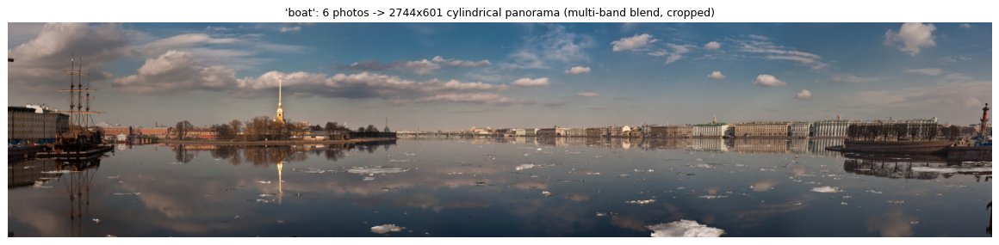

In [17]:
def show_pano(img, title, width=13):
    h, w = img.shape[:2]
    # We size the figure to the aspect ratio of the panorama, so wide panoramas are not squashed.
    fig = plt.figure(figsize=(width, width * h / w + 0.5))
    plt.imshow(to_rgb(img)); plt.axis("off"); plt.title(title)
    plt.tight_layout(); plt.show()


r = RESULTS["boat"]
show_pano(r["panorama"], f"'boat': 6 photos -> {r['panorama'].shape[1]}x{r['panorama'].shape[0]} cylindrical panorama (multi-band blend, cropped)")

### 9.1 What the warp stage does (boat)
Each photo is re-projected into the shared panorama frame. Left: outline of every photo on the canvas (the reference image is the thick one). Below: the individual warped photos before blending; the overlaps are the regions where blending decides what to show.

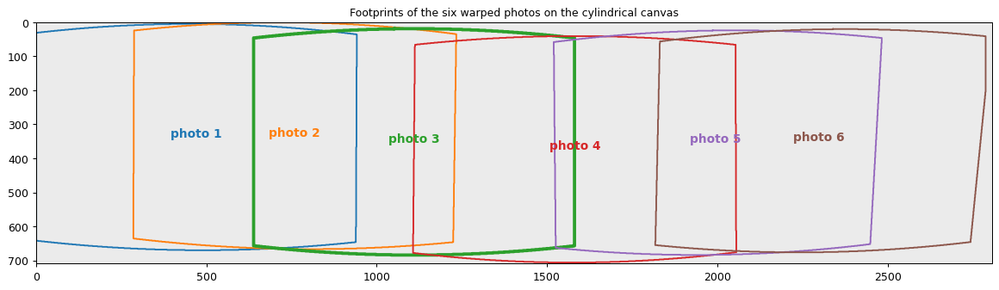

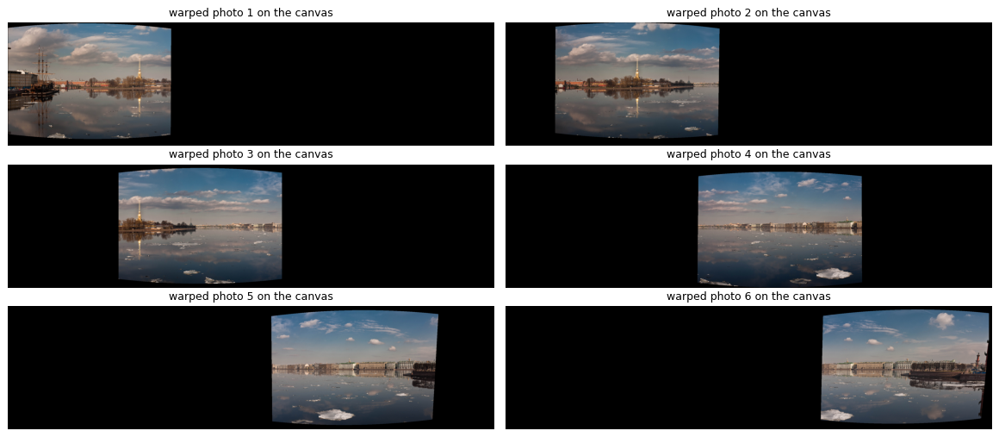

In [18]:
def plot_layout(r, title):
    order, offsets, patches, masks = r["order"], r["offsets"], r["patches"], r["masks"]
    Wc, Hc = r["layout"]["size"]
    fig, ax = plt.subplots(figsize=(13, 13 * Hc / Wc + 0.6))
    ax.imshow(np.zeros((Hc, Wc, 3), np.uint8) + 235)
    # We draw the outline of every warped photo on an empty canvas and we write the photo number in its middle; the
    # thick outline is the reference photo.
    cols = plt.cm.tab10(np.arange(len(order)))
    for n, (k, p, m, o) in enumerate(zip(order, patches, masks, offsets)):
        # We trace the outline of each photo from its mask.
        cnt, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for c in cnt:
            c = c[:, 0, :] + np.array(o)
            ax.plot(*np.r_[c, c[:1]].T, color=cols[n], lw=3 if k == r["align"]["ref"] else 1.5)
        cy, cx = np.argwhere(m).mean(0)
        ax.text(cx + o[0], cy + o[1], f"photo {k+1}", color=cols[n], ha="center", fontsize=11, weight="bold")
    ax.set_xlim(0, Wc); ax.set_ylim(Hc, 0); ax.set_title(title)
    plt.tight_layout(); plt.show()


plot_layout(RESULTS["boat"], "Footprints of the six warped photos on the cylindrical canvas")


def photos_on_canvas(r):
    Wc, Hc = r["layout"]["size"]
    out = []
    for p, o in zip(r["patches"], r["offsets"]):
        # We paste each warped photo alone on a black canvas, so we can see where it ends up and where the
        # overlaps are.
        c = np.zeros((Hc, Wc, 3), np.uint8)
        c[paste_slice(o, p.shape)] = p
        out.append(c)
    return out


show_images(photos_on_canvas(RESULTS["boat"]), [f"warped photo {k+1} on the canvas" for k in RESULTS["boat"]["order"]],
            ncols=2, cell=(6.5, 1.9))

### 9.2 Blending comparison (boat)
Same geometry, four ways of combining it. Zoom-ins are taken around the overlap between the reference photo and its neighbour. Seams from exposure differences are visible with **naive overlay**; **gain compensation** reduces the brightness step (a faint seam can remain if the photos are simply pasted over each other); **feathering** and **multi-band blending** hide the transition. Multi-band blending is designed to mix low frequencies over wide regions and high frequencies over narrow ones, so edges are not smeared: judge the zoom-ins by eye (the PSNR numbers in section 10 do not score seam visibility).

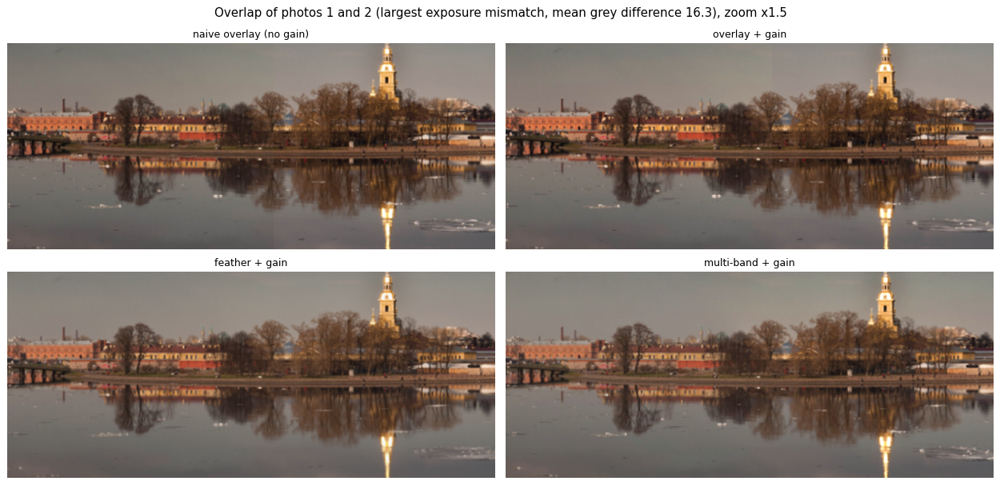

overlap grey-level error over all overlaps (lower = exposure more consistent): no gain 11.75 -> with gain 7.13
estimated gains per photo (columns B, G, R):
[[0.936 0.92  0.917]
 [1.037 1.037 1.047]
 [1.006 1.005 1.006]
 [1.06  1.067 1.064]
 [0.964 0.966 0.961]
 [0.936 0.938 0.93 ]]


In [19]:
def pick_seam_pair(r):
    """Tree-edge pair of warped photos (positions in r['order']) with the largest exposure mismatch before gain compensation."""
    # We look for the pair of neighbouring photos whose exposure differs most, because that is where the blending
    # matters most.
    pos = {k: n for n, k in enumerate(r["order"])}
    best, best_e = None, -1.0
    for a, b in r["align"]["tree"]:
        pa, pb = pos[a], pos[b]
        e = overlap_error([r["patches"][pa], r["patches"][pb]], [r["masks"][pa], r["masks"][pb]], [r["offsets"][pa], r["offsets"][pb]])
        if np.isfinite(e) and e > best_e:
            best, best_e = (pa, pb), e
    return best, best_e


def overlap_window(r, a, b, max_w=520, height=220):
    """Window covering the whole overlap of two warped photos (centred vertically on the busiest image rows)."""
    oa, ob, pa, pb = r["offsets"][a], r["offsets"][b], r["patches"][a], r["patches"][b]
    # We cut a window that covers the whole overlap of the two photos, so the seam is guaranteed to be inside it.
    x0, y0 = max(oa[0], ob[0]), max(oa[1], ob[1])
    x1, y1 = min(oa[0] + pa.shape[1], ob[0] + pb.shape[1]), min(oa[1] + pa.shape[0], ob[1] + pb.shape[0])
    Wc, Hc = r["layout"]["size"]
    w = min(x1 - x0, max_w)
    xs = int(np.clip((x0 + x1) // 2 - w // 2, 0, Wc - w))
    # We centre the window vertically on the rows with the most detail (the strongest vertical gradients), because
    # seams are easiest to judge there.
    grey = cv2.cvtColor(r["full"][y0:y1, x0:x1], cv2.COLOR_BGR2GRAY).astype(np.float32)
    energy = np.abs(np.diff(grey, axis=0)).sum(1)
    energy = np.convolve(energy, np.ones(height // 2), mode="same")
    ys = int(np.clip(y0 + int(np.argmax(energy)) - height // 2, 0, Hc - height))
    return xs, ys, w, height


def blend_comparison(r):
    (a, b), e0 = pick_seam_pair(r)
    wh = r["layout"]["size"]
    # We blend the same warped photos four ways: first without any exposure compensation, then with our gains.
    variants = {
        "naive overlay (no gain)": blend_overlay(r["patches"], r["masks"], r["offsets"], wh),
        "overlay + gain": blend_overlay(r["patches_gain"], r["masks"], r["offsets"], wh),
        "feather + gain": blend_feather(r["patches_gain"], r["masks"], r["offsets"], wh),
        "multi-band + gain": blend_multiband(r["patches_gain"], r["masks"], r["offsets"], wh),
    }
    # We zoom into the overlap, to compare the four methods side by side.
    xs, ys, w, h = overlap_window(r, a, b)
    crops = [cv2.resize(v[ys:ys + h, xs:xs + w], None, fx=1.5, fy=1.5, interpolation=cv2.INTER_CUBIC) for v in variants.values()]
    show_images(crops, list(variants.keys()), ncols=2, cell=(7.0, 3.5),
                suptitle=f"Overlap of photos {r['order'][a]+1} and {r['order'][b]+1} (largest exposure mismatch, mean grey difference {e0:.1f}), zoom x1.5")
    return variants


# We run this comparison on the boat panorama.
_variants = blend_comparison(RESULTS["boat"])
print("overlap grey-level error over all overlaps (lower = exposure more consistent): "
      f"no gain {RESULTS['boat']['overlap_err'][0]:.2f} -> with gain {RESULTS['boat']['overlap_err'][1]:.2f}")
print("estimated gains per photo (columns B, G, R):")
print(np.round(RESULTS["boat"]["gains"], 3))

### 9.3 Cropping the black borders (church interior, set 'a')

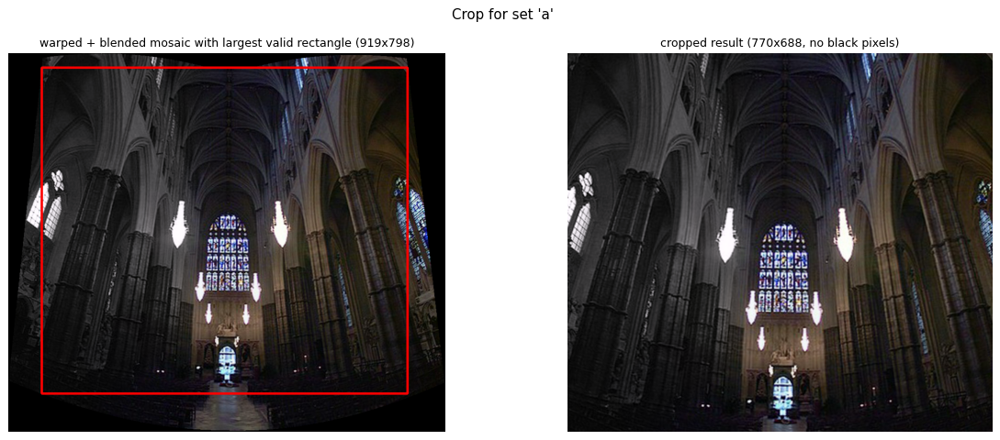

boat       canvas 2807x709 -> crop 2744x601 (83% of canvas), black pixels inside crop: 0


budapest   canvas 2064x1045 -> crop 2044x987 (94% of canvas), black pixels inside crop: 0
newspaper  canvas 1592x1009 -> crop 1580x987 (97% of canvas), black pixels inside crop: 0
a          canvas 919x798 -> crop 770x688 (72% of canvas), black pixels inside crop: 0


In [20]:
def show_crop(r, title):
    # We draw the rectangle we crop to in red on the uncropped mosaic, and next to it we show the cropped result.
    full = r["full"].copy()
    x0, y0, x1, y1 = r["rect"]
    cv2.rectangle(full, (x0, y0), (x1 - 1, y1 - 1), (0, 0, 255), 3)
    show_images([full, r["panorama"]], [f"warped + blended mosaic with largest valid rectangle ({full.shape[1]}x{full.shape[0]})",
                                        f"cropped result ({r['panorama'].shape[1]}x{r['panorama'].shape[0]}, no black pixels)"],
                ncols=2, cell=(6.8, 5.4), suptitle=title)


show_crop(RESULTS["a"], "Crop for set 'a'")
# We report how much of the canvas we keep, and we count the black pixels left inside the crop (it must be zero).
for _n, _r in RESULTS.items():
    x0, y0, x1, y1 = _r["rect"]
    print(f"{_n:10s} canvas {_r['full'].shape[1]}x{_r['full'].shape[0]} -> crop {x1-x0}x{y1-y0} "
          f"({100*(x1-x0)*(y1-y0)/(_r['full'].shape[0]*_r['full'].shape[1]):.0f}% of canvas), black pixels inside crop: {int((~_r['mask'][y0:y1, x0:x1]).sum())}")

### 9.4 All results

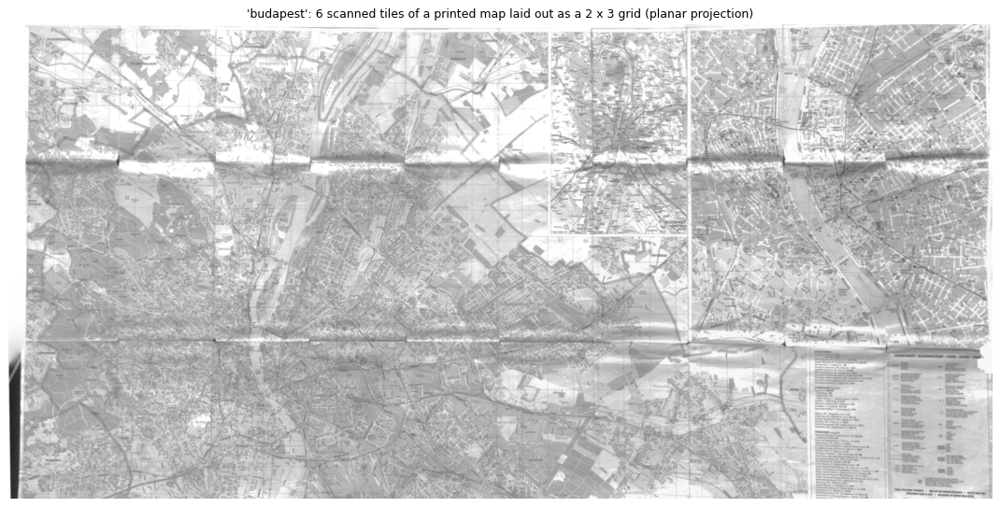

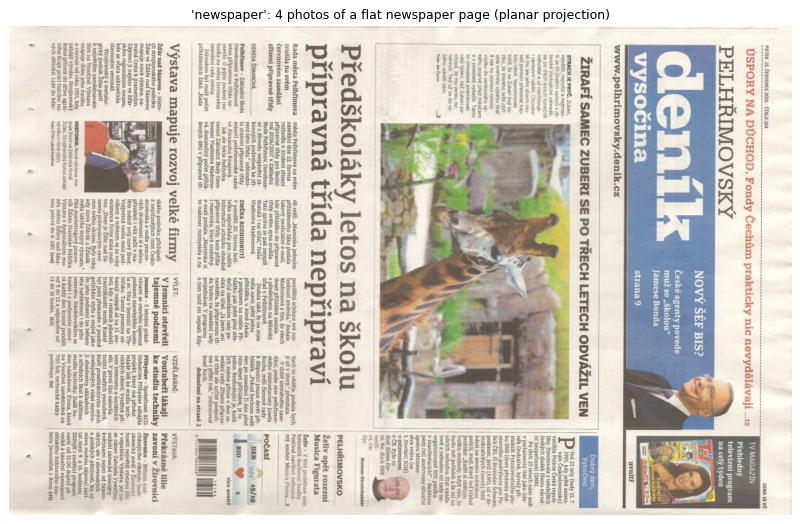

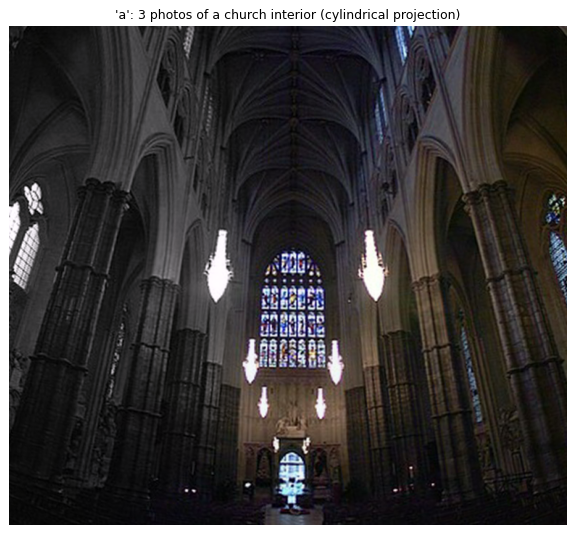

In [21]:
show_pano(RESULTS["budapest"]["panorama"], "'budapest': 6 scanned tiles of a printed map laid out as a 2 x 3 grid (planar projection)", width=12)
show_pano(RESULTS["newspaper"]["panorama"], "'newspaper': 4 photos of a flat newspaper page (planar projection)", width=9)
show_pano(RESULTS["a"]["panorama"], "'a': 3 photos of a church interior (cylindrical projection)", width=6.5)

In [22]:
# We summarise every run in one table: projection, focal length, alignment error, exposure error before and after, canvas
# size and time.
print(f"{'set':10s} {'imgs':>4s} {'proj':>11s} {'focal px':>9s} {'edges':>5s} {'min inl':>8s} {'refine px':>16s} {'overlap err':>14s} {'canvas':>11s} {'time s':>7s}")
for n, r in RESULTS.items():
    al = r["align"]
    inl = [al["pairs"][(min(a, b), max(a, b))]["inliers"] for a, b in al["tree"]]
    f = r["proj_info"]["f"]
    f_txt = "n/a" if f >= 5900 else f"{f:.0f}"          # n/a: for a flat scene the rotation model does not fit, and our search hit its upper bound
    print(f"{n:10s} {len(r['order']):4d} {r['projection'].name:>11s} {f_txt:>9s} {len(al['tree']):5d} {min(inl):8d} "
          f"{al['refine']['before']:6.2f} -> {al['refine']['after']:5.2f} {r['overlap_err'][0]:6.2f} -> {r['overlap_err'][1]:5.2f} "
          f"{r['full'].shape[1]:5d}x{r['full'].shape[0]:<5d} {sum(r['timing'].values()):7.1f}")

set        imgs        proj  focal px edges  min inl        refine px    overlap err      canvas  time s
boat          6 cylindrical      1157     5      226   1.51 ->  0.98  11.75 ->  7.13  2807x709       5.8
budapest      6      planar      2709     5      577   2.96 ->  1.34  16.37 -> 15.52  2064x1045     12.1
newspaper     4      planar       n/a     3      709   0.32 ->  0.32   8.54 ->  8.29  1592x1009      6.5
a             3 cylindrical       585     2      926   1.20 ->  1.15  10.83 -> 10.56   919x798       2.5


### 9.5 SIFT versus ORB
The pipeline accepts either detector (`detector="sift"` or `"orb"` in `stitch`). SIFT descriptors are 128 floats built in a scale space and give sub-pixel localisation; ORB descriptors are 256-bit strings compared with the Hamming distance, which is cheaper per comparison but less precisely localised. Same pair, same matcher (Hamming distance for ORB), same RANSAC. Compare the inlier count and the **RMSE** (lower = more precise alignment) in the table; note that on this low-texture water/sky pair SIFT's default contrast threshold keeps fewer keypoints than the 4000-keypoint ORB budget.

In [23]:
# We compare the two detectors on one pair of boat photos, with the same matcher and the same RANSAC.
_ia, _ib = 3, 4     # boat photos 4 and 5
# For each detector we time the detection separately from the matching and RANSAC.
rows = []
for det in ("sift", "orb"):
    t0 = time.time()
    fa_, fb_ = detect_features(IMAGES["boat"][_ia], det, 4000), detect_features(IMAGES["boat"][_ib], det, 4000)
    t_feat = time.time() - t0
    t0 = time.time()
    p = estimate_pair(fa_, fb_)
    rows.append((det.upper(), len(fa_["pts"]), len(fb_["pts"]), p["n_match"], p["inliers"], p["rmse"], t_feat, time.time() - t0, p["accepted"]))
print(f"{'detector':9s} {'kp A':>6s} {'kp B':>6s} {'matches':>8s} {'inliers':>8s} {'RMSE px':>8s} {'detect s':>9s} {'match+RANSAC s':>15s} accepted")
for r_ in rows:
    print(f"{r_[0]:9s} {r_[1]:6d} {r_[2]:6d} {r_[3]:8d} {r_[4]:8d} {r_[5]:8.2f} {r_[6]:9.2f} {r_[7]:15.2f} {r_[8]}")

detector    kp A   kp B  matches  inliers  RMSE px  detect s  match+RANSAC s accepted
SIFT        1310   1880      493      460     0.88      0.20            0.08 True
ORB         4000   4000      621      571     1.21      0.23            0.36 True


### 9.6 Baseline: OpenCV's own `cv2.Stitcher` (reference only)
For context only: the black-box stitcher of OpenCV on the same photos. Our result is produced entirely by the code above; this is **not** used anywhere in the pipeline.

cv2.Stitcher status 0 (0 = OK), 0.8s, output (2756, 685)


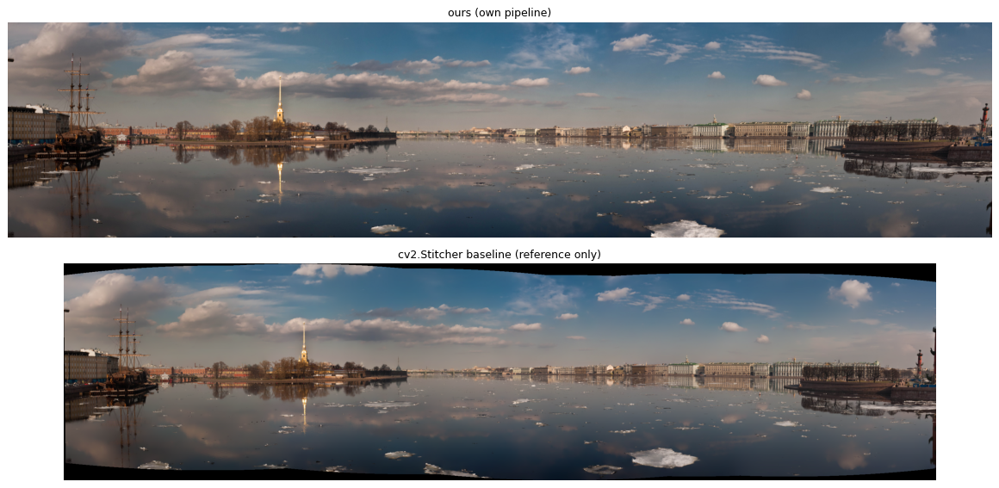

In [24]:
try:
    t0 = time.time()
    # We run OpenCV's built-in stitcher on the same photos purely as a reference, and we do not use its output
    # anywhere in our own pipeline.
    stt = cv2.Stitcher_create(cv2.Stitcher_PANORAMA)
    status, base = stt.stitch(IMAGES["boat"])
    dt_base = time.time() - t0
    print(f"cv2.Stitcher status {status} (0 = OK), {dt_base:.1f}s, output {None if base is None else base.shape[:2][::-1]}")
    if status == 0:
        BASELINE_BOAT = base
        show_images([RESULTS["boat"]["panorama"], base], ["ours (own pipeline)", "cv2.Stitcher baseline (reference only)"], ncols=1, cell=(13, 3.2))
except Exception as e:
    print("cv2.Stitcher not available or failed:", e)

## 10. Validation: is it actually working right?

Pretty panoramas can hide wrong geometry, so every component is tested against something we know to be true:

| # | Test | Ground truth |
|---|---|---|
| T1-T2 | DLT on exact and noisy correspondences | known `H` |
| T3 | RANSAC with 30 / 50 / 70 % random outliers | known `H` and known outlier labels |
| T4 | own matcher vs OpenCV `BFMatcher` | OpenCV's nearest neighbours / ratio test |
| T5 | own bilinear warp vs `cv2.warpPerspective` | OpenCV's pixels |
| T6 | image-level: SIFT + matcher + RANSAC on a photo warped with a known `H` (also with exposure change and noise) | known `H` |
| T7 | gain compensation recovers known exposure factors; nearest-fill and largest-rectangle correct | brute force / known factors |
| T8 | **synthetic panorama**: 4 views cut from one big photo with known homographies, random order, different exposure, noise | known `H`, known scene |
| T9 | real data: all images connected, sensible ordering, low reprojection error, crop has no black pixels | physical constraints |
| T10 | comparison with `cv2.findHomography` on the same matches | independent implementation |

Each test prints a line and is recorded in the summary table at the end of the section.

[PASS] T1 DLT recovers H exactly from noise-free points (4 pts and 60 pts) | corner error 4.1e-13 px / 4.3e-13 px
[PASS] T2 DLT with 100 points and 0.5 px Gaussian noise (20 trials) | mean corner error 0.191 px, worst 0.311 px


[PASS] T3 RANSAC with 30% random outliers (10 trials) | corner error mean 0.140 / worst 0.207 px, inlier precision 1.000, recall 1.000


[PASS] T3 RANSAC with 50% random outliers (10 trials) | corner error mean 0.182 / worst 0.269 px, inlier precision 1.000, recall 1.000


[PASS] T3 RANSAC with 70% random outliers (10 trials) | corner error mean 0.258 / worst 0.376 px, inlier precision 1.000, recall 1.000


[PASS] T4 own matcher agrees with cv2.BFMatcher.knnMatch (nearest neighbour index and ratio-test decision) | 1-NN identical for 100.00% of descriptors, ratio-test decision identical for 100.00%
[PASS] T5 own bilinear inverse warp matches cv2.warpPerspective | mean abs difference 0.064 grey levels over 353524 pixels


[PASS] T6 SIFT + matcher + RANSAC recovers a known homography (clean) | corner error 0.056 px, 1157/1161 inliers
[PASS] T6 SIFT + matcher + RANSAC recovers a known homography (exposure x0.75 + noise sigma 4) | corner error 0.042 px, 771/785 inliers
[PASS] T7a gain compensation removes known exposure differences (gains 1.0 / 0.8 / 1.2) | estimated gains [0.918 1.1   0.797], residual spread of gain x true gain = 3.4%
[PASS] T7b nearest-valid-pixel fill is exact (brute force on 200 pixels) | 0 mismatches


[PASS] T7c largest valid rectangle equals the brute-force optimum (150 random masks) | 0 mismatches


views shown to the pipeline in the order (original ids): [0, 2, 1, 3]


    4/4 images connected | reference = image 2 | tree [(1, 3), (3, 2), (2, 4)] | refinement 0.20->0.20px
    focal estimate f = 3837.5 px, rotation-model misfit 0.202, planar span 32 deg -> planar


    canvas 2194x750 (scale 1.00) | cropped 2164x613 | overlap grey error 30.04 -> 5.18 | gains (rows=images) min 0.845 max 1.126 | total 2.4s
[PASS] T8a synthetic panorama: estimated view-to-reference homographies match ground truth (shuffled input order) | corner error per view [0.    0.498 0.193 1.086] px, all 4/4 views used
[PASS] T8b synthetic panorama: gain compensation undoes the injected exposure changes | residual spread 3.2% (gains [0.928 0.85  1.121 1.057])


    PSNR vs ground-truth mosaic, overlay, no gain compensation :  27.56 dB
    PSNR vs ground-truth mosaic, overlay + gain                :  34.52 dB
    PSNR vs ground-truth mosaic, feather + gain                :  34.96 dB
    PSNR vs ground-truth mosaic, multi-band + gain             :  34.29 dB
    note: feathering can score slightly higher than multi-band here, likely because averaging the overlapping views also averages their independent noise; PSNR does not measure seam visibility.
[PASS] T8c synthetic panorama: gain compensation + blending is closer to the true scene than naive overlay | multi-band 34.3 dB, feather 35.0 dB, naive overlay 27.6 dB


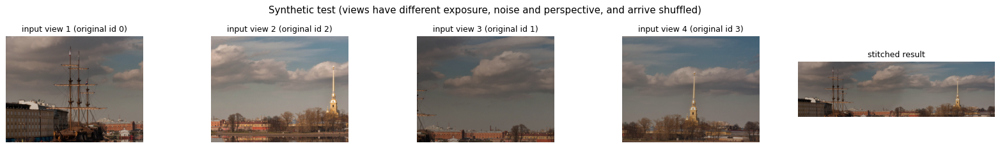

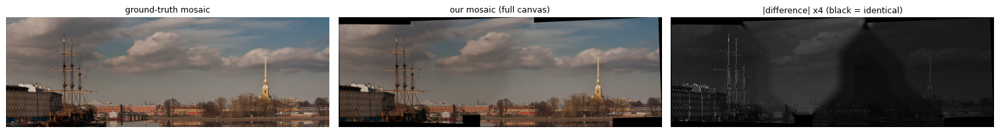

In [25]:
# We collect every test result in a list, so we can print one summary table at the end.
TESTS = []


def check(name, passed, detail=""):
    TESTS.append((name, bool(passed), detail))
    print(f"[{'PASS' if passed else 'FAIL'}] {name} | {detail}")


def corner_error(Ha, Hb, w, h):
    """Mean distance (px) between two homographies, measured at the image corners and centre."""
    # We compare two homographies by where they send the four corners and the centre of an image.
    pts = np.array([[0, 0], [w, 0], [w, h], [0, h], [w / 2, h / 2]], float)
    return float(np.linalg.norm(apply_h(Ha, pts) - apply_h(Hb, pts), axis=1).mean())


# We invent a realistic ground-truth homography (a bit of rotation, scale, shift and perspective) and we use it in the
# next tests.
H_TRUE = np.array([[1.08, 0.12, 35.0], [-0.07, 0.95, -22.0], [1.2e-4, -6e-5, 1.0]])
W0, H0 = 1000, 700
rng = np.random.default_rng(1)

# --- T1: exact data ---------------------------------------------------------------------------
# T1: we give the DLT perfect, noise-free points and we check that it recovers the homography exactly, with 4 points and
# with 60.
src4 = rng.uniform(0, [W0, H0], (4, 2)); dst4 = apply_h(H_TRUE, src4)
srcN = rng.uniform(0, [W0, H0], (60, 2)); dstN = apply_h(H_TRUE, srcN)
e4, eN = corner_error(dlt_homography(src4, dst4), H_TRUE, W0, H0), corner_error(dlt_homography(srcN, dstN), H_TRUE, W0, H0)
check("T1 DLT recovers H exactly from noise-free points (4 pts and 60 pts)", e4 < 1e-6 and eN < 1e-6, f"corner error {e4:.1e} px / {eN:.1e} px")

# --- T2: noisy data ---------------------------------------------------------------------------
# T2: we add 0.5 px of Gaussian noise to 100 points and we repeat this 20 times; the DLT should stay far below one pixel.
errs = []
for s in range(20):
    r_ = np.random.default_rng(100 + s)
    sp = r_.uniform(0, [W0, H0], (100, 2)); dp = apply_h(H_TRUE, sp) + r_.normal(0, 0.5, (100, 2))
    errs.append(corner_error(dlt_homography(sp, dp), H_TRUE, W0, H0))
check("T2 DLT with 100 points and 0.5 px Gaussian noise (20 trials)", np.mean(errs) < 1.0, f"mean corner error {np.mean(errs):.3f} px, worst {np.max(errs):.3f} px")

# --- T3: RANSAC with outliers -----------------------------------------------------------------
# T3: we replace 30, 50 and 70 percent of the matches by random points, and we check that RANSAC still finds the right
# homography and labels the outliers correctly.
for frac in (0.3, 0.5, 0.7):
    errs, prec, rec = [], [], []
    for s in range(10):
        r_ = np.random.default_rng(200 + s)
        n = 200
        sp = r_.uniform(0, [W0, H0], (n, 2)); dp = apply_h(H_TRUE, sp) + r_.normal(0, 0.5, (n, 2))
        out = r_.permutation(n)[: int(frac * n)]
        dp[out] = r_.uniform(0, [W0, H0], (len(out), 2))             # replace by random points = outliers
        truth = np.ones(n, bool); truth[out] = False
        H_, inl, _ = ransac_homography(sp, dp, thresh=3.0, seed=s)
        errs.append(corner_error(H_, H_TRUE, W0, H0))
        prec.append((inl & truth).sum() / max(inl.sum(), 1)); rec.append((inl & truth).sum() / truth.sum())
    check(f"T3 RANSAC with {int(frac*100)}% random outliers (10 trials)", np.max(errs) < 2.0 and np.mean(prec) > 0.95 and np.mean(rec) > 0.9,
          f"corner error mean {np.mean(errs):.3f} / worst {np.max(errs):.3f} px, inlier precision {np.mean(prec):.3f}, recall {np.mean(rec):.3f}")

# --- T4: matcher vs OpenCV --------------------------------------------------------------------
fa, fb = FEATS["budapest"][0], FEATS["budapest"][1]
# T4: we compare our matcher with OpenCV's BFMatcher; we switch the mutual check off, so that both use exactly the same
# ratio test.
mine = match_descriptors(fa["desc"], fb["desc"], "l2", ratio=0.75, mutual=False)
bf = cv2.BFMatcher(cv2.NORM_L2).knnMatch(fa["desc"], fb["desc"], k=2)
cv_nn = np.array([m_[0].trainIdx for m_ in bf])
cv_pass = np.array([m_[0].distance < 0.75 * m_[1].distance for m_ in bf])
my_pass = np.zeros(len(cv_pass), bool); my_pass[mine["matches"][:, 0]] = True
agree_nn = float((mine["all_nn"][:, 1] == cv_nn).mean())
agree_pass = float((my_pass == cv_pass).mean())
check("T4 own matcher agrees with cv2.BFMatcher.knnMatch (nearest neighbour index and ratio-test decision)",
      agree_nn > 0.995 and agree_pass > 0.995, f"1-NN identical for {100*agree_nn:.2f}% of descriptors, ratio-test decision identical for {100*agree_pass:.2f}%")

# --- T5: warp vs OpenCV -----------------------------------------------------------------------
# T5: we warp one image with our own warp and with cv2.warpPerspective, and we compare the pixels.
img = IMAGES["a"][0]
Hw = np.array([[1.05, 0.04, 20.0], [-0.03, 0.98, 10.0], [2e-4, 1e-4, 1.0]])
lay = layout_canvas([(img.shape[1], img.shape[0])], {0: Hw}, PlanarProjection())
mine_w, mine_m, (ox, oy) = warp_to_canvas(img, Hw, PlanarProjection(), lay)
Wc, Hc = lay["size"]
T_ = np.array([[1, 0, -lay["origin"][0]], [0, 1, -lay["origin"][1]], [0, 0, 1.0]])
cvw = cv2.warpPerspective(img, T_ @ Hw, (Wc, Hc), flags=cv2.INTER_LINEAR)
full_mine = np.zeros((Hc, Wc, 3), np.uint8); full_mask = np.zeros((Hc, Wc), bool)
sl = paste_slice((ox, oy), mine_w.shape); full_mine[sl] = mine_w; full_mask[sl] = mine_m
# We compare only pixels that are valid in both results and a few pixels away from the border, where interpolation
# conventions could differ.
inner = cv2.erode(full_mask.astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool) & (cv2.warpPerspective(np.ones(img.shape[:2], np.uint8), T_ @ Hw, (Wc, Hc)) > 0)
mad = float(np.abs(full_mine[inner].astype(float) - cvw[inner].astype(float)).mean())
check("T5 own bilinear inverse warp matches cv2.warpPerspective", mad < 1.0, f"mean abs difference {mad:.3f} grey levels over {int(inner.sum())} pixels")

# --- T6: image-level known-H test ---------------------------------------------------------------
# T6: we warp a real photo with a known homography G and we ask the full chain (SIFT, matcher, RANSAC) to find G again; in
# the second version we also change the exposure and add noise.
base_img = IMAGES["boat"][0]
th = np.radians(4.0)
G = np.array([[1.05 * np.cos(th), -1.05 * np.sin(th), 60.0], [1.05 * np.sin(th), 1.05 * np.cos(th), 15.0], [8e-5, -4e-5, 1.0]])
warped_img = cv2.warpPerspective(base_img, G, (base_img.shape[1], base_img.shape[0]))
variants = {"clean": warped_img,
            "exposure x0.75 + noise sigma 4": np.clip(warped_img.astype(np.float32) * 0.75 + np.random.default_rng(5).normal(0, 4, warped_img.shape), 0, 255).astype(np.uint8)}
fa6 = detect_features(base_img)
for label, wi in variants.items():
    p = estimate_pair(fa6, detect_features(wi))
    # evaluate on the region that exists in both images
    e = corner_error(p["H"], G, 600, 400) if p["H"] is not None else np.inf
    check(f"T6 SIFT + matcher + RANSAC recovers a known homography ({label})", e < 1.0 and p["accepted"],
          f"corner error {e:.3f} px, {p['inliers']}/{p['n_match']} inliers")

# --- T7: gain compensation / fill / crop --------------------------------------------------------
# T7a: we cut three overlapping pieces from one photo and we darken or brighten them by known factors; the gain
# compensation must find those factors again.
true_gain = np.array([1.0, 0.8, 1.2])
base = IMAGES["boat"][2][:, :800]
shifts = [0, 200, 400]
pt, mk, of = [], [], []
for g, sx in zip(true_gain, shifts):
    crop_ = base[:, sx:sx + 400]
    pt.append(np.clip(crop_.astype(np.float32) * g, 0, 255).astype(np.uint8)); mk.append(np.ones(crop_.shape[:2], bool)); of.append((sx, 0))
gains_est, _ = compute_gains(pt, mk, of)
ratio_ = gains_est[:, 1] * true_gain                         # should be constant (any common factor is irrelevant)
cv_ = float(np.std(ratio_) / np.mean(ratio_))
check("T7a gain compensation removes known exposure differences (gains 1.0 / 0.8 / 1.2)", cv_ < 0.05,
      f"estimated gains {np.round(gains_est[:, 1], 3)}, residual spread of gain x true gain = {100*cv_:.1f}%")
# T7b: we check the nearest-pixel fill against a brute-force search over all valid pixels.
m_ = np.random.default_rng(3).random((40, 60)) > 0.4
p_ = np.random.default_rng(4).integers(0, 255, (40, 60, 3), dtype=np.uint8)
filled = fill_invalid_nearest(p_, m_)
yy, xx = np.nonzero(~m_)
vy, vx = np.nonzero(m_)
bad = 0
for y, x in zip(yy[:200], xx[:200]):
    d2 = (vy - y) ** 2 + (vx - x) ** 2
    cand = np.nonzero(d2 == d2.min())[0]
    bad += not any((p_[vy[c], vx[c]] == filled[y, x]).all() for c in cand)
check("T7b nearest-valid-pixel fill is exact (brute force on 200 pixels)", bad == 0 and (filled[m_] == p_[m_]).all(), f"{bad} mismatches")
# T7c: we check the largest-rectangle routine against an exhaustive search on 150 small random masks.
mism = 0
for trial in range(150):
    r_ = np.random.default_rng(trial)
    mk_ = r_.random((r_.integers(4, 11), r_.integers(4, 13))) > 0.25
    H_, W_ = mk_.shape
    best = 0
    for y0 in range(H_):
        for y1 in range(y0 + 1, H_ + 1):
            for x0 in range(W_):
                for x1 in range(x0 + 1, W_ + 1):
                    if mk_[y0:y1, x0:x1].all():
                        best = max(best, (y1 - y0) * (x1 - x0))
    if not mk_.any():
        continue
    x0, y0, x1, y1 = largest_valid_rectangle(mk_, max_dim=10 ** 6)
    mism += (not mk_[y0:y1, x0:x1].all()) or ((x1 - x0) * (y1 - y0) != best)
check("T7c largest valid rectangle equals the brute-force optimum (150 random masks)", mism == 0, f"{mism} mismatches")

# --- T8: synthetic panorama with ground truth ---------------------------------------------------
# T8 is the big test: we cut four overlapping views out of one large photo with known homographies, we change their
# exposure, we add noise and we shuffle them, and then we see whether the pipeline recovers the geometry, the exposure and
# the scene.
scene = cv2.resize(cv2.imread(os.path.join(DATA_DIR, "boat1.jpg")), (2400, 1600), interpolation=cv2.INTER_AREA)
scene = (scene.astype(np.float32) * 0.85).astype(np.uint8)
VW, VH = 900, 700
x_off = [60, 580, 1100, 1440]
y_off = [220, 180, 240, 200]
tilt = [(-1.2, 1.00, 0.0, 0.0), (0.8, 1.03, 2e-5, -1e-5), (-0.5, 0.97, -2e-5, 1.5e-5), (1.5, 1.02, 1e-5, 2e-5)]
true_exposure = [1.00, 0.80, 1.15, 0.90]
Gs, views = [], []
c0 = np.array([[1, 0, VW / 2], [0, 1, VH / 2], [0, 0, 1.0]])
for k in range(4):
    ang, sc, p1, p2 = tilt[k]
    a = np.radians(ang)
    Hp = np.array([[sc * np.cos(a), -sc * np.sin(a), 0], [sc * np.sin(a), sc * np.cos(a), 0], [p1, p2, 1.0]])
    Gk = c0 @ Hp @ np.linalg.inv(c0) @ np.array([[1, 0, -x_off[k]], [0, 1, -y_off[k]], [0, 0, 1.0]])
    v = cv2.warpPerspective(scene, Gk, (VW, VH), flags=cv2.INTER_LINEAR)
    v = np.clip(v.astype(np.float32) * true_exposure[k] + np.random.default_rng(10 + k).normal(0, 2.0, v.shape), 0, 255).astype(np.uint8)
    Gs.append(Gk); views.append(v)
# We shuffle the views, so the pipeline cannot rely on the input order.
perm = np.random.default_rng(7).permutation(4)                      # feed the views in a random order
print("views shown to the pipeline in the order (original ids):", perm.tolist())
# We force the planar frame here, because our ground truth lives in a plane.
syn = stitch([views[i] for i in perm], projection="planar", verbose=True)
# We compare each estimated homography with the ground-truth one, expressed relative to the same reference view.
ref_s = syn["align"]["ref"]
# We collect the corner error of every view.
errs = []
for k, Hk in syn["align"]["H"].items():
    gt = Gs[perm[ref_s]] @ np.linalg.inv(Gs[perm[k]])
    errs.append(corner_error(Hk, gt, VW, VH))
check("T8a synthetic panorama: estimated view-to-reference homographies match ground truth (shuffled input order)",
      len(syn["order"]) == 4 and max(errs) < 2.0, f"corner error per view {np.round(errs, 3)} px, all {len(syn['order'])}/4 views used")
gains_syn = syn["gains"][:, 1]
exp_perm = np.array([true_exposure[i] for i in perm])
cvg = float(np.std(gains_syn * exp_perm[syn['order']]) / np.mean(gains_syn * exp_perm[syn['order']]))
check("T8b synthetic panorama: gain compensation undoes the injected exposure changes", cvg < 0.05, f"residual spread {100*cvg:.1f}% (gains {np.round(gains_syn, 3)})")

# We build the ground-truth mosaic in the same canvas frame as our result, by warping the original photo with the true
# homography.
(umin, vmin), sc_ = syn["layout"]["origin"], syn["layout"]["scale"]
Wc, Hc = syn["layout"]["size"]
M_gt = np.array([[1, 0, -umin], [0, 1, -vmin], [0, 0, 1.0]]) @ Gs[perm[ref_s]]
gt_pano = cv2.warpPerspective(scene, M_gt, (Wc, Hc), flags=cv2.INTER_LINEAR)
gt_valid = cv2.warpPerspective(np.ones(scene.shape[:2], np.uint8), M_gt, (Wc, Hc)) > 0
use = syn["mask"] & gt_valid
use = cv2.erode(use.astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool)


# We measure how close each blend is to the true scene (PSNR, higher is better), after removing the arbitrary global
# brightness.
def psnr_vs_gt(img):
    a = img[use].astype(np.float64)
    b = gt_pano[use].astype(np.float64)
    a = a * (b.mean(0) / a.mean(0))                                  # remove the arbitrary global exposure
    mse = np.mean((a - b) ** 2)
    return 10 * np.log10(255 ** 2 / mse)


wh = syn["layout"]["size"]
psnr = {"overlay, no gain compensation": psnr_vs_gt(blend_overlay(syn["patches"], syn["masks"], syn["offsets"], wh)),
        "overlay + gain": psnr_vs_gt(blend_overlay(syn["patches_gain"], syn["masks"], syn["offsets"], wh)),
        "feather + gain": psnr_vs_gt(blend_feather(syn["patches_gain"], syn["masks"], syn["offsets"], wh)),
        "multi-band + gain": psnr_vs_gt(blend_multiband(syn["patches_gain"], syn["masks"], syn["offsets"], wh))}
for k_, v_ in psnr.items():
    print(f"    PSNR vs ground-truth mosaic, {k_:30s}: {v_:6.2f} dB")
print("    note: feathering can score slightly higher than multi-band here, likely because averaging the overlapping views also averages their independent noise; PSNR does not measure seam visibility.")
check("T8c synthetic panorama: gain compensation + blending is closer to the true scene than naive overlay",
      psnr["multi-band + gain"] > psnr["overlay, no gain compensation"] + 0.5 and psnr["feather + gain"] > psnr["overlay, no gain compensation"] + 0.5,
      f"multi-band {psnr['multi-band + gain']:.1f} dB, feather {psnr['feather + gain']:.1f} dB, naive overlay {psnr['overlay, no gain compensation']:.1f} dB")
show_images([views[i] for i in perm] + [syn["panorama"]], [f"input view {n+1} (original id {perm[n]})" for n in range(4)] + ["stitched result"],
            ncols=5, cell=(3.6, 2.6), suptitle="Synthetic test (views have different exposure, noise and perspective, and arrive shuffled)")
diff = np.abs(syn["full"].astype(np.float32) - gt_pano.astype(np.float32)).mean(2) * 4
diff[~use] = 0
show_images([gt_pano, syn["full"], np.clip(diff, 0, 255).astype(np.uint8)],
            ["ground-truth mosaic", "our mosaic (full canvas)", "|difference| x4 (black = identical)"], ncols=3, cell=(5.6, 2.6))

In [26]:
# --- T9: real data ------------------------------------------------------------------------------
# T9: on the real photos we have no ground truth, so we test physical constraints instead: everything is connected, the
# alignment error is small, and the crop has no empty pixels.
for name, r in RESULTS.items():
    al, n = r["align"], len(IMAGES[name])
    check(f"T9a '{name}': all {n} photos are connected into one panorama", len(al["component"]) == n, f"component {[c+1 for c in al['component']]}")
    rm = [al["pairs"][(min(a, b), max(a, b))]["rmse"] for a, b in al["tree"]]
    check(f"T9b '{name}': inlier reprojection RMSE of every tree edge < 2 px and global mean transfer error < 2 px",
          max(rm) < 2.0 and al["refine"]["after"] < 2.0, f"edge RMSE max {max(rm):.2f} px, global mean error {al['refine']['after']:.2f} px")
    x0, y0, x1, y1 = r["rect"]
    check(f"T9c '{name}': cropped panorama contains no black (invalid) pixels", bool(r["mask"][y0:y1, x0:x1].all()), f"{x1-x0}x{y1-y0}")

# ordering test: shuffled photos of 'boat' -> centres must appear left-to-right in the physical order (or exactly reversed)
# We shuffle the six boat photos and we check that we still get them in left-to-right order, which the pipeline has to
# work out by itself.
perm_b = np.random.default_rng(11).permutation(6)
rb = stitch([IMAGES["boat"][i] for i in perm_b], verbose=False)
cent = {}
for pos, k in enumerate(rb["order"]):
    ys_, xs_ = np.nonzero(rb["masks"][pos])
    cent[int(perm_b[k])] = xs_.mean() + rb["offsets"][pos][0]
seq = sorted(cent, key=cent.get)
check("T9d 'boat' photos given in random order are placed left-to-right in the true physical order", seq == list(range(6)) or seq == list(range(5, -1, -1)),
      f"input order {perm_b.tolist()} -> panorama order {seq}")

# We check that the six scanned map tiles end up as a 2 x 3 grid in reading order; this is also why the spanning tree is
# branched instead of a chain.
rb_ = RESULTS["budapest"]
cent_b = {}
for pos, k in enumerate(rb_["order"]):
    ys_, xs_ = np.nonzero(rb_["masks"][pos])
    cent_b[k] = (xs_.mean() + rb_["offsets"][pos][0], ys_.mean() + rb_["offsets"][pos][1])
grid_ok = (max(cent_b[k][1] for k in (0, 1, 2)) < min(cent_b[k][1] for k in (3, 4, 5))
           and cent_b[0][0] < cent_b[1][0] < cent_b[2][0] and cent_b[3][0] < cent_b[4][0] < cent_b[5][0])
check("T9f 'budapest' tiles form a 2 x 3 grid in reading order (photos 1-3 on the top row, 4-6 below, each row left to right)", grid_ok,
      "centroids (x, y): " + ", ".join(f"{k+1}:({cent_b[k][0]:.0f},{cent_b[k][1]:.0f})" for k in sorted(cent_b)))

# We mix a newspaper photo in among the harbour photos; we expect the pipeline to leave it out instead of forcing it into
# the panorama.
mixed = [IMAGES["boat"][0], IMAGES["newspaper"][0], IMAGES["boat"][1], IMAGES["boat"][2]]
rm_ = stitch(mixed, verbose=False)
check("T9e an unrelated photo mixed into 3 boat photos is detected and left out (no false matches accepted)",
      rm_["align"]["dropped"] == [1] and len(rm_["order"]) == 3, f"dropped image index {rm_['align']['dropped']}, used {[k for k in rm_['order']]}")

# --- T10: our RANSAC vs cv2.findHomography on identical matches ---------------------------------
# We score both models with the SAME function (MSAC cost = sum of min(symmetric error^2, 3px^2) over all matches; lower is
# better),
# and we compare them where the data is: on the matches that BOTH methods call inliers. (Raw inlier counts are not
# comparable: OpenCV thresholds the
# forward error, ours the symmetric error. Distances at far image corners are not meaningful either, they are
# extrapolations.)
# We use the same scoring function for both implementations, so the comparison is fair.
def msac_cost(H_, s_, d_, t=3.0):
    return float(np.minimum(symmetric_transfer_error(H_, s_, d_) ** 2, t ** 2).sum())


rows = []
for name in ("boat", "budapest", "newspaper", "a"):
    al = RESULTS[name]["align"]
    for a, b in al["tree"]:
        i, j = min(a, b), max(a, b)
        mm_ = match_descriptors(FEATS[name][i]["desc"], FEATS[name][j]["desc"], "l2", 0.75, True)["matches"]
        s_, d_ = FEATS[name][i]["pts"][mm_[:, 0]], FEATS[name][j]["pts"][mm_[:, 1]]
        Hc_, mk_ = cv2.findHomography(s_, d_, cv2.RANSAC, 3.0)
        runs = [ransac_homography(s_, d_, 3.0, seed=sd) for sd in range(5)]     # RANSAC is randomised, so we run it with 5 seeds and we judge the median
        costs = [msac_cost(r_[0], s_, d_) for r_ in runs]
        k_med = int(np.argsort(costs)[len(costs) // 2])
        H_own, inl_own, _ = runs[k_med]
        common = inl_own & (mk_.ravel() > 0)
        gap = np.linalg.norm(apply_h(H_own, s_[common]) - apply_h(Hc_, s_[common]), axis=1)
        rows.append((name, f"{i+1}-{j+1}", int(inl_own.sum()), int(mk_.sum()), int(common.sum()), costs[k_med], msac_cost(Hc_, s_, d_), float(gap.mean()), min(costs), max(costs)))
print(f"{'set':10s} {'pair':>5s} {'inl own':>8s} {'inl cv2':>8s} {'common':>7s} {'MSAC own (median)':>18s} {'own min..max':>14s} {'MSAC cv2':>9s} {'gap on common inliers (mean px)':>32s}")
for r_ in rows:
    print(f"{r_[0]:10s} {r_[1]:>5s} {r_[2]:8d} {r_[3]:8d} {r_[4]:7d} {r_[5]:18.0f} {r_[8]:6.0f}..{r_[9]:<6.0f} {r_[6]:9.0f} {r_[7]:32.2f}")
check("T10a own RANSAC (median of 5 seeds) reaches an MSAC cost within 2% of, or below, cv2.findHomography on every tree edge (same scoring function, same matches)",
      all(r_[5] <= 1.02 * r_[6] for r_ in rows), f"worst cost ratio own/cv2 = {max(r_[5] / r_[6] for r_ in rows):.3f}; own is lower on {sum(r_[5] < r_[6] for r_ in rows)} of {len(rows)} edges")
check("T10b the two independent implementations agree within 1.5 px on average on the matches both accept as inliers",
      all(r_[7] < 1.5 for r_ in rows), f"worst mean gap {max(r_[7] for r_ in rows):.2f} px over {len(rows)} edges")

[PASS] T9a 'boat': all 6 photos are connected into one panorama | component [1, 2, 3, 4, 5, 6]
[PASS] T9b 'boat': inlier reprojection RMSE of every tree edge < 2 px and global mean transfer error < 2 px | edge RMSE max 0.88 px, global mean error 0.98 px
[PASS] T9c 'boat': cropped panorama contains no black (invalid) pixels | 2744x601
[PASS] T9a 'budapest': all 6 photos are connected into one panorama | component [1, 2, 3, 4, 5, 6]
[PASS] T9b 'budapest': inlier reprojection RMSE of every tree edge < 2 px and global mean transfer error < 2 px | edge RMSE max 1.25 px, global mean error 1.34 px
[PASS] T9c 'budapest': cropped panorama contains no black (invalid) pixels | 2044x987
[PASS] T9a 'newspaper': all 4 photos are connected into one panorama | component [1, 2, 3, 4]
[PASS] T9b 'newspaper': inlier reprojection RMSE of every tree edge < 2 px and global mean transfer error < 2 px | edge RMSE max 0.37 px, global mean error 0.32 px
[PASS] T9c 'newspaper': cropped panorama contains no black

[PASS] T9d 'boat' photos given in random order are placed left-to-right in the true physical order | input order [3, 1, 4, 5, 2, 0] -> panorama order [0, 1, 2, 3, 4, 5]
[PASS] T9f 'budapest' tiles form a 2 x 3 grid in reading order (photos 1-3 on the top row, 4-6 below, each row left to right) | centroids (x, y): 1:(509,371), 2:(1075,373), 3:(1541,375), 4:(516,673), 5:(1053,666), 6:(1547,657)


[PASS] T9e an unrelated photo mixed into 3 boat photos is detected and left out (no false matches accepted) | dropped image index [1], used [0, 2, 3]


set         pair  inl own  inl cv2  common  MSAC own (median)   own min..max  MSAC cv2  gap on common inliers (mean px)
boat         1-2      515      517     515                445    445..445          451                             0.06
boat         2-3      366      366     366                844    844..844          844                             0.00
boat         3-4      226      226     226                338    338..359          347                             0.11
boat         4-5      449      449     449                646    640..662          646                             0.01
boat         5-6      626      656     560               1314   1314..1314        1663                             0.88
budapest     1-4      948      948     948                375    375..375          382                             0.07
budapest     4-5      553      548     548               1448   1448..1455        1457                             0.11
budapest     2-5      872      872     8

In [27]:
# We print every test with its verdict and the total, so a failure cannot hide.
n_pass = sum(t[1] for t in TESTS)
print(f"\n{'Test':120s} Result")
for name_, ok_, det_ in TESTS:
    print(f"{name_[:118]:120s} {'PASS' if ok_ else 'FAIL'}")
print(f"\n{n_pass} / {len(TESTS)} checks passed" + ("" if n_pass == len(TESTS) else "   <-- some checks FAILED, see the log above"))


Test                                                                                                                     Result
T1 DLT recovers H exactly from noise-free points (4 pts and 60 pts)                                                      PASS
T2 DLT with 100 points and 0.5 px Gaussian noise (20 trials)                                                             PASS
T3 RANSAC with 30% random outliers (10 trials)                                                                           PASS
T3 RANSAC with 50% random outliers (10 trials)                                                                           PASS
T3 RANSAC with 70% random outliers (10 trials)                                                                           PASS
T4 own matcher agrees with cv2.BFMatcher.knnMatch (nearest neighbour index and ratio-test decision)                      PASS
T5 own bilinear inverse warp matches cv2.warpPerspective                                                           

## 11. Try your own photos

Set `USE_OWN_PHOTOS = True` and run the cell. On Colab it opens an upload dialog; locally it reads every image in the folder `my_photos/`.

Tips for good input: rotate the camera about its own position (not your body), keep 30-50 % overlap between neighbouring shots, lock exposure/white balance/focus if you can, and avoid moving objects in the overlaps. Photos may be given in any order.

In [28]:
# We leave this switched off by default, so 'Run all' only uses the public dataset.
USE_OWN_PHOTOS = False      # <- set to True to stitch your own photos
OWN_DIR = "my_photos"


def load_own_photos(max_side=1000):
    # On Colab we ask for an upload and we save the photos into the folder; locally we simply read the folder.
    if IN_COLAB:
        from google.colab import files
        os.makedirs(OWN_DIR, exist_ok=True)
        for fname, data in files.upload().items():          # pick two or more overlapping photos
            with open(os.path.join(OWN_DIR, fname), "wb") as fh:
                fh.write(data)
    # We read the images in name order; the order does not matter for stitching, because the pipeline finds the
    # overlaps by itself.
    names = sorted(f for f in os.listdir(OWN_DIR) if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")))
    if len(names) < 2:
        raise FileNotFoundError(f"put at least two overlapping photos into ./{OWN_DIR}/")
    out = []
    for n in names:
        im = cv2.imread(os.path.join(OWN_DIR, n))
        s = max_side / max(im.shape[:2])
        out.append(cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else im)
    return out


# We stitch the photos with the same stitch() function that we used for the public sets.
if USE_OWN_PHOTOS:
    own = load_own_photos()
    res_own = stitch(own, projection="auto")
    cv2.imwrite(f"{RESULTS_DIR}/panorama_own.png", res_own["panorama"])
    show_pano(res_own["panorama"], "your panorama")
else:
    print("USE_OWN_PHOTOS is False: skipped.")

USE_OWN_PHOTOS is False: skipped.


## 12. Summary, design notes and limitations

**What was built.** A complete, from-scratch panorama pipeline: SIFT/ORB features, own brute-force matcher with Lowe ratio test and mutual check, own normalized-DLT homography with own MSAC/RANSAC (adaptive iteration count, degenerate-sample rejection, symmetric transfer error, LM polish), a match graph with maximum-spanning-tree ordering so photos can arrive in any order, global homography refinement, focal-length estimation from the homographies, planar or cylindrical projection chosen automatically, own bilinear inverse warping, per-channel gain compensation, feathering and multi-band blending, and largest-rectangle cropping.

**How it was checked.** Section 10 tests each stage against ground truth (known homographies, brute-force searches, OpenCV's own functions as independent references) and runs a synthetic panorama with known geometry and exposure. All checks, and the figures above, are produced by the cells in this notebook.

**Design choices worth knowing**
* *Symmetric transfer error* in RANSAC prevents a degenerate `H` that collapses points from scoring well.
* *Maximum spanning tree + tree-centre reference* keeps the chain of multiplied homographies short and built from the strongest overlaps; the global refinement then removes the small inconsistencies that remain.
* *Cylindrical projection* is chosen only when the rotation model fits (`K^-1 H K` close to a rotation) **and** the planar mosaic would span more than about 75 degrees; flat scenes (the map and the newspaper) correctly stay planar.
* *Multi-band blending* fills invalid pixels with the nearest valid colour before building pyramids so black borders cannot bleed into the seams.

**Known limitations**
* Pure homographies assume a rotating camera or a flat scene. Parallax (near and far objects with a translating camera) or moving objects (the drifting ice in the harbour set) cannot be aligned perfectly and may leave faint ghosting; a graph-cut seam finder would reduce it.
* The refinement adjusts homographies only (no shared camera intrinsics / full bundle adjustment), so very long sequences or 360 degree panoramas would accumulate drift and would need spherical projection and loop closure.
* Gain compensation is one gain per image and channel: vignetting and local exposure changes are left to the multi-band blend.
* Image sets with almost no texture (blank walls, clear sky) provide too few matches; the pipeline then reports the images that could not be connected instead of producing a wrong panorama.